# Build GRNs to understand how lung immunce cells work

## 1. Preparation of individual input files in `data` folder
After data processing with CellRanger, you need the following files:
* RNA read count matrix ("Filtered feature barcode matrix MEX (DIR)")
* ATAC reads ("ATAC Position-sorted alignments (BAM)")
* Optionally or from other softwares: cell clustering (inside "Secondary analysis outputs (DIR)")


In [1]:
# Removes CPU usage limit by some jupyter versions
import os
os.environ['KMP_AFFINITY'] = ''
#Create input data folder
!mkdir ../data


### expression.tsv.gz
Read count matrix of RNA-profiled cells in compressed tsv format. Downloaded and converted from "Filtered feature barcode matrix MEX (DIR)".

In [2]:
%%bash
cd ../data
# Download expression data in mtx.gz format
wget -q -o /dev/null https://cf.10xgenomics.com/samples/cell-arc/2.0.0/pbmc_granulocyte_sorted_10k/pbmc_granulocyte_sorted_10k_filtered_feature_bc_matrix.tar.gz
tar xf pbmc_granulocyte_sorted_10k_filtered_feature_bc_matrix.tar.gz
rm pbmc_granulocyte_sorted_10k_filtered_feature_bc_matrix.tar.gz
# Convert from mtx.gz to tsv.gz format using helper script `expression_mtx.py`.
dictys_helper expression_mtx.py filtered_feature_bc_matrix expression.tsv.gz
rm -Rf filtered_feature_bc_matrix


### bams
This folder contains one bam file for each cell with chromatin accessibility measurement. File name should be cell name. Downloaded and converted from "ATAC Position-sorted alignments (BAM)".
* **This step can take hours or even over a day**
* The default setting will need ~30GB of memory for this dataset. Specify a lower `--buffer_size 1000` or smaller for `dictys_helper split_bam.sh` if you have less memory.


In [3]:
%%bash
set -eo pipefail
cd ../data
# Download chromatin accessibility reads in bam format
wget -q -o /dev/null -O bams.bam https://s3-us-west-2.amazonaws.com/10x.files/samples/cell-arc/2.0.0/pbmc_granulocyte_sorted_10k/pbmc_granulocyte_sorted_10k_atac_possorted_bam.bam
# Split bam file to individual bam files for each cell using helper script `split_bam.sh`
dictys_helper split_bam.sh bams.bam bams --section "CB:Z:" --ref_expression expression.tsv.gz
rm bams.bam


### subsets & subsets.txt
* subsets.txt: Names of cell subsets. For each cell subset, a GRN is reconstructed.
* subsets: Folder containing one subfolder for each cell subset as in `subsets.txt`. Each subfolder contains two files:
    - names_rna.txt: Names of cells that belong to this subset and have transcriptome measurement
    - names_atac.txt: Names of cells that belong to this subset and have chromatin accessibility measurement
    - For joint measurements of RNA and ATAC, these two files should be identical in every folder.
    
Option 1: download the clustering from 10x "Secondary analysis outputs (DIR)":

In [4]:
%%bash
cd ../data
wget -q -o /dev/null https://cf.10xgenomics.com/samples/cell-arc/2.0.0/pbmc_granulocyte_sorted_10k/pbmc_granulocyte_sorted_10k_analysis.tar.gz
#Extract cell names for each cluster
tar xf pbmc_granulocyte_sorted_10k_analysis.tar.gz 
mv analysis/clustering/gex/graphclust/clusters.csv clusters.csv
rm -Rf pbmc_granulocyte_sorted_10k_analysis.tar.gz analysis


Option 2: cluster with other softwares (here [scanpy](https://scanpy-tutorials.readthedocs.io/en/latest/pbmc3k.html) below).

**Note**:
* The cell below can be hidden if you use a renderer other than jupyter (e.g. github).
* If you don't have scanpy installed, the kernel would automatically restart to finish scanpy installation. Please continue by running this cell again for clustering.

Finally, reformat clusters.csv for input:

In [5]:
%%bash
cd ../data
subsets="$(tail -n +2 clusters.csv | awk -F , '{print $2}' | sort -u)"
echo "$subsets" | awk '{print "Subset"$1}' > subsets.txt
for x in $subsets; do
	mkdir -p "subsets/Subset$x"
	grep ",$x"'$' clusters.csv | awk -F , '{print $1}' > "subsets/Subset$x/names_rna.txt"
	# RNA and ATAC barcodes are the same for joint quantifications
	cp "subsets/Subset$x/names_rna.txt" "subsets/Subset$x/names_atac.txt"
done
rm clusters.csv


### Customized to U19 dataset

In [ ]:
#assign unique barcodes to each cell in read count matrix
lung_list<-read.table("/home/jinggu/scripts/bash/dictys/data_list.txt")
new_expr<-expr
for(i in 2:6){
    expr<-read.table(sprintf("/home/jinggu/scratch/projects/dictys/data/%s/expression.tsv.gz", 
    lung_list$V1[i]))
    ids<-unlist(lapply(colnames(expr), function(i){strsplit(i, "[.]")[[1]][1]}))
    colnames(expr)<-paste(paste(ids, i, sep=("-")), "1", sep="_")
    new_expr<-cbind(new_expr, expr)
}
spleen_list<-read.table("/home/jinggu/scripts/bash/dictys/spleen_list.txt")
for(i in 1:3){
    expr<-read.table(sprintf("/home/jinggu/scratch/projects/dictys/data/%s/expression.tsv.gz", 
    spleen_list$V1[i]))
    ids<-unlist(lapply(colnames(expr), function(i){strsplit(i, "[.]")[[1]][1]}))
    colnames(expr)<-paste(paste(ids, i, sep=("-")), "2", sep="_")
    new_expr<-cbind(new_expr, expr)
}
write.table(expr, gzfile("/home/jinggu/scratch/projects/dictys/data/expression.tsv.gz"), row.names=FALSE, quote = F, sep="\t")

### Other files
Motif, reference genome, gene transcriptional start site

In [6]:
%%bash
cd ../data

# Motifs (file motifs.motif)
# Option 1: from HOCOMOCO (https://hocomoco11.autosome.org/)
wget -q -o /dev/null -O motifs.motif 'https://hocomoco11.autosome.org/final_bundle/hocomoco11/full/HUMAN/mono/HOCOMOCOv11_full_HUMAN_mono_homer_format_0.0001.motif'
# Option 2: from HOMER
# dictys_helper motif_homer.sh > motifs.motif
# Option 3: provide your custom motifs

# Reference genome (folder genome)
# Note: You need the same reference genome version with chromatin accessibility reads
# Option 1: download genome from HOMER
dictys_helper genome_homer.sh hg38 genome
# Option 2: provide your custom genome

# Bed file for TSS (file gene.bed)
# Download gtf file from ensembl
wget -q -o /dev/null -O gene.gtf.gz http://ftp.ensembl.org/pub/release-107/gtf/homo_sapiens/Homo_sapiens.GRCh38.107.gtf.gz
gunzip gene.gtf.gz
# Convert to bed
dictys_helper gene_gtf.sh gene.gtf gene.bed
rm gene.gtf


### Clean up

In [7]:
!rm -Rf ../data/filtered_feature_bc_matrix


## 2. Network inference configuration
### Generate configurations
Please adjust them for your own machine and dataset

In [8]:
%%bash
# Generate configuration template
rm -Rf ../makefiles
mkdir ../makefiles
cd ../makefiles
dictys_helper makefile_template.sh common.mk config.mk env_none.mk static.mk

# Update configurations, such as:
# DEVICE: pytorch device, e.g. cpu, cuda:0. If you do not have a GPU, use 'cpu' and expect LONG computing time.
# GENOME_MACS2: effective genome size for macs2. See https://deeptools.readthedocs.io/en/develop/content/feature/effectiveGenomeSize.html
# JOINT: whether dataset is joint profiling of RNA and ATAC.
# Other configurations include quality control thresholds, number of threads in each job, number of hidden confounders, etc.
# They can be obtained in the full-multiome tutorial.
dictys_helper makefile_update.py ../makefiles/config.mk '{"DEVICE": "cuda:0", "GENOME_MACS2": "hs", "JOINT": "1"}'


### Validate input data

In [9]:
!cd .. && dictys_helper makefile_check.py

Joint profile: True
Found 11898 cells with RNA profile
Found 24036 genes with RNA profile
Found 11898 cells with ATAC profile
Found 769 motifs
Found 678 TFs
Found 461 TFs in current dataset
Missing 217 TFs in current dataset: ANDR,AP2A,AP2B,AP2C,AP2D,ARI3A,ARI5B,ATF6A,BARH1,BARH2,BC11A,BHA15,BHE22,BHE23,BHE40,BHE41,BMAL1,BRAC,BSH,COE1,COT1,COT2,CR3L1,CR3L2,ERR1,ERR2,ERR3,EVI1,GCR,HEN1,HMBX1,HME1,HME2,HNF6,HTF4,HXA1,HXA10,HXA11,HXA13,HXA2,HXA5,HXA7,HXA9,HXB1,HXB13,HXB2,HXB3,HXB4,HXB6,HXB7,HXB8,HXC10,HXC11,HXC12,HXC13,HXC6,HXC8,HXC9,HXD10,HXD11,HXD12,HXD13,HXD3,HXD4,HXD8,HXD9,ITF2,KAISO,MCR,MGAP,MLXPL,MYBA,MYBB,NDF1,NDF2,NF2L1,NF2L2,NFAC1,NFAC2,NFAC3,NFAC4,NGN2,NKX21,NKX22,NKX23,NKX25,NKX28,NKX31,NKX32,NKX61,NKX62,ONEC2,ONEC3,OZF,P53,P5F1B,P63,P73,PEBB,PHX2A,PHX2B,PIT1,PKNX1,PLAL1,PO2F1,PO2F2,PO2F3,PO3F1,PO3F2,PO3F3,PO3F4,PO4F1,PO4F2,PO4F3,PO5F1,PO6F1,PO6F2,PRD14,PRGR,RHXF1,RORG,RX,SMCA1,SMCA5,SRBP1,SRBP2,STA5A,STA5B,STF1,SUH,TF2LX,TF65,TF7L1,TF7L2,TFE2,THA,THA11,THB,TWST1,TYY1,TYY2,UBIP

## 3. Network inference
* **This step can take a day or longer**. You are strongly suggested to use a GPU. If it takes over a day, see [FAQ](https://github.com/pinellolab/dictys#faq) to improve speed.
* Please adjust `-j n_jobs` for your machine. The total thread count is n_jobs*n_threads. By default n_threads=4.


In [10]:
!cd ..; dictys_helper network_inference.sh -j 32 -J 1 static 

mkdir -p tmp_static/Subset1/
cp data/subsets/Subset1/names_rna.txt tmp_static/Subset1/names_rna.txt
mkdir -p tmp_static/Subset10/
cp data/subsets/Subset10/names_rna.txt tmp_static/Subset10/names_rna.txt
mkdir -p tmp_static/Subset11/
cp data/subsets/Subset11/names_rna.txt tmp_static/Subset11/names_rna.txt
mkdir -p tmp_static/Subset12/
cp data/subsets/Subset12/names_rna.txt tmp_static/Subset12/names_rna.txt
mkdir -p tmp_static/Subset13/
cp data/subsets/Subset13/names_rna.txt tmp_static/Subset13/names_rna.txt
mkdir -p tmp_static/Subset14/
cp data/subsets/Subset14/names_rna.txt tmp_static/Subset14/names_rna.txt
mkdir -p tmp_static/Subset2/
cp data/subsets/Subset2/names_rna.txt tmp_static/Subset2/names_rna.txt
mkdir -p tmp_static/Subset3/
cp data/subsets/Subset3/names_rna.txt tmp_static/Subset3/names_rna.txt
mkdir -p tmp_static/Subset4/
cp data/subsets/Subset4/names_rna.txt tmp_static/Subset4/names_rna.txt
mkdir -p tmp_static/Subset5/
cp data/subsets/Subset5/names_rna.txt tmp_static/Subset5

## 4. Network analysis
Note: network inference depends on many factors, e.g. pseudo-randomness, randomness, and software version. Your figures may vary from those shown here.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dictys.plot.static import compute_spec
from dictys.plot import dotplot
from dictys.net import network
import pandas as pd
import seaborn as sns
import os
#Load networks
d0=network.from_file("/home/jinggu/cluster/projects/u19_multiomics/analyses/remove_dup/dictys/static.h5")
deg,deg_spec,cpm,cpm_spec,regmarker,regmarker_state = compute_spec(d0,nmax=20,vmin=0,ncut=0.4,min_entropy=0.8,sparsity=0.02) #select_state = select_state)

#Rename cell subsets
d_names = {}
for i in deg.columns:
    d_names[i] = i.split("Subset")[1]
d0.rename('s', d_names)
#Regulation markers based on TF regulatory activity (by target count) and its specificity
#Color map of specificity
cmap='spring_r'
#Node sizes to draw legend in dot plot
node_size_deg=[20,100,200,500]
#Transformation from target count to node size
node_size_map_deg=lambda x:x*(x<=10)+(10+(x-10)*500/10/490)*(x>10)

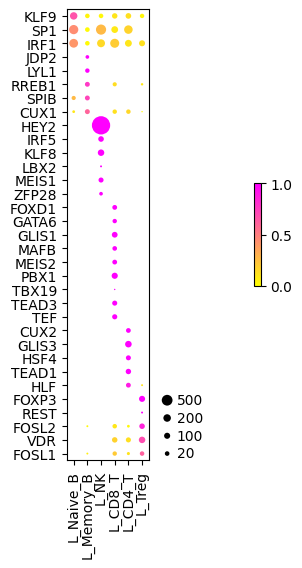

In [2]:
#Find marker genes based on regulatory activity specificity
select_state = 'L_Naive_B,L_Memory_B,L_NK,L_CD8_T,L_CD4_T,L_Treg'.split(',')
#Arguments control how many top markers to show and the cutoffs for target count, its specificity at the most abundant cell subset, and its entropy over all cell subsets
deg,deg_spec,cpm,cpm_spec,regmarker,regmarker_state = compute_spec(d0,nmax=5,vmin=0,ncut=0.4,min_entropy=0.9,sparsity=0.02, select_state = select_state)
#Draw dot plot with regulatory activity and its specificity
fig,ax=dotplot(deg.loc[regmarker].iloc[::-1],deg_spec.loc[regmarker].iloc[::-1],size_transform=node_size_map_deg,sizes=np.array(node_size_deg),cmap=cmap)


In [31]:
str(np.arange(0.01, 0.035, 0.005)[3])

'0.024999999999999998'

In [36]:
select_state = [f"L_{i}" for i in 'Naive_B,Memory_B,NK,CD8_T,CD4_T'.split(',')]
grn_path = "../../output/output_dir/remove_dup/dictys"
d = {}
for i in np.round(np.arange(0.01, 0.036, 0.005), 3):
    deg,deg_spec,cpm,cpm_spec,regmarker,regmarker_state = compute_spec(d0,nmax=50,ncut=0.4,sparsity=i, select_state = select_state)
    if not os.path.isdir(f"{grn_path}/sparsity{i}"):
        os.mkdir(f"{grn_path}/sparsity{i}")
    pd.DataFrame.to_csv(
        pd.DataFrame({"RegMarker": regmarker,
                      "CellType" : regmarker_state}),
        f"{grn_path}/sparsity{i}/lung_GRN_regulatory_markers.csv", index = False)

### Specifics about the parameters
deg: target count obtained from weighted network   
dcrate: degree centrality rate   
deg_spec: degree centrality sepcificity     
`(dcrate.T/(dcrate.sum(axis=1)+1E-300)).T`

CPM: `cpm=2**(stat.lcpm(d0,cut=-1,constant=1).compute(select_state))-1`   
CPM specificity: cpm_spec=(cpm.T/(cpm.sum(axis=1)+1E-300)).T

## 5. Results Summary

In [3]:
from functools import partial
import numpy as np
from dictys.net.layout import _fruchterman_reingold
from dictys.net import stat
from dictys.plot import panel

def retrieve_edges_GRNs(state, sparsity_value=0.02):
    pts=np.array([d0.sdict[state]])
    stat1_net=stat.net(d0)
    stat1_netbin=stat.fbinarize(stat1_net,sparsity=sparsity_value)
    #Subnetwork
    stat1_subnet,stat1_subnetbin=stat1_net,stat1_netbin
    transformation=lambda x:x
    stat1_subnet_trunc=stat.function(lambda *x:transformation(x[0]*x[1]),[stat1_subnet,stat1_subnetbin],names=stat1_subnet.names)
    edges=stat1_subnet_trunc.compute(pts)[:,:,0]
    t1=np.nonzero(edges)
    edges=pd.DataFrame([stat1_subnet_trunc.names[0][t1[0]],stat1_subnet_trunc.names[1][t1[1]],edges[t1[0],t1[1]]],index=['Regulator','Target','Strength']).T
    return(edges)


def make_group_hist(dict, x_label=None, xticks=None, nbins = 20):
    """
    histogram plots arranged into two rows
    """
    fig,axs = plt.subplots(2,(len(dict)+1)//2, sharey=True, sharex=True, tight_layout=True)
    
    for i in range(0, len(dict), 2):
        ctype=list(dict.keys())[i]
        axs[0, i//2].hist(list(dict[ctype]), bins = nbins)
        if xticks is not None:
            axs[0, i//2].set_xticks(xticks)
        axs[0, i//2].set_title(ctype)
        quantiles = np.quantile(dict[ctype], q = [0.25, 0.75])
        plt.xlim([quantiles[0], quantiles[1]])
        
    for i in range(1, len(dict), 2):
        j=(i-1)//2
        ctype=list(dict.keys())[i]
        axs[1, j].hist(list(dict[ctype]), bins = nbins)
        if xticks is not None:
            axs[1, j].set_xticks(xticks)
        axs[1, j].set_title(ctype)
        # Rotate the tick labels and set their alignment.
        plt.setp(axs[1, j].get_xticklabels(), rotation=45, ha="right",
         rotation_mode="anchor")
        quantiles = np.quantile(dict[ctype], q = [0.25, 0.75])
        plt.xlim([quantiles[0], quantiles[1]])
    #axs[0,1].set(xlabel=x_label)
    axs[1,1].set(xlabel=x_label)

### Distribution of target gene statistics across TFs at different sparsity levels

In [3]:
deg,deg_spec,cpm,cpm_spec,regmarker,regmarker_state=compute_spec(d0,nmax=0,vmin=10,ncut=0.25,min_entropy=1)

In [25]:
ct_order=["Naive_B", "Memory_B", "NK", "CD8_T", "CD4_T", "Treg"]
d_edges={}
for c in ct_order:
    d_edges[f"L_{c}"]=retrieve_edges_GRNs(f"L_{c}", sparsity_value=0.02)

d_targets={}
d_regs={}
for c in d_edges.keys():
    target_sets=d_edges[c].groupby("Regulator", group_keys=True)[["Target"]].apply(lambda x: set(x.iloc[:,0]))
    d_targets[c]=np.array([len(i) for i in target_sets])
    reg_sets=d_edges[c].groupby("Target", group_keys=True)[["Regulator"]].apply(lambda x: set(x.iloc[:,0]))
    d_regs[c]=np.array([len(i) for i in reg_sets])

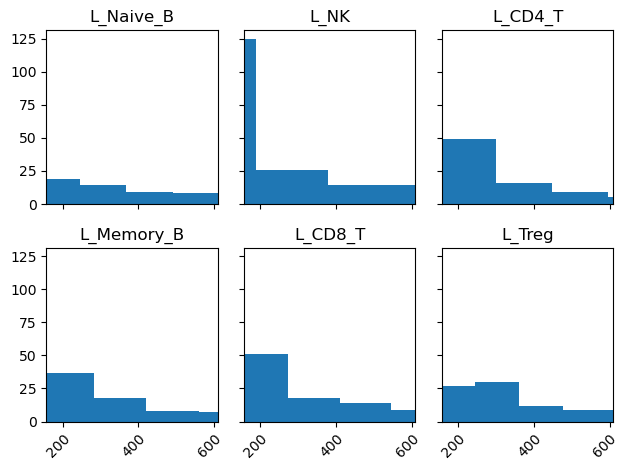

In [26]:
make_group_hist(d_targets)#xticks=range(0, 500, 100))

### sparsity = 0.02

In [27]:
make_group_hist(d_targets, xmax = 2000)

TypeError: make_group_hist() got an unexpected keyword argument 'xmax'

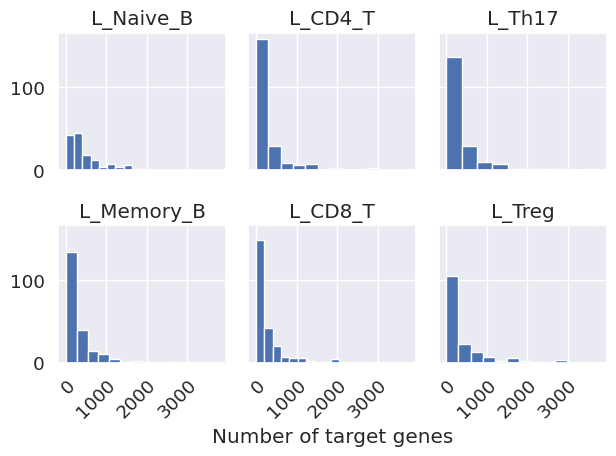

In [45]:
make_group_hist(d_targets, "Number of target genes", range(0, 3500, 1000))

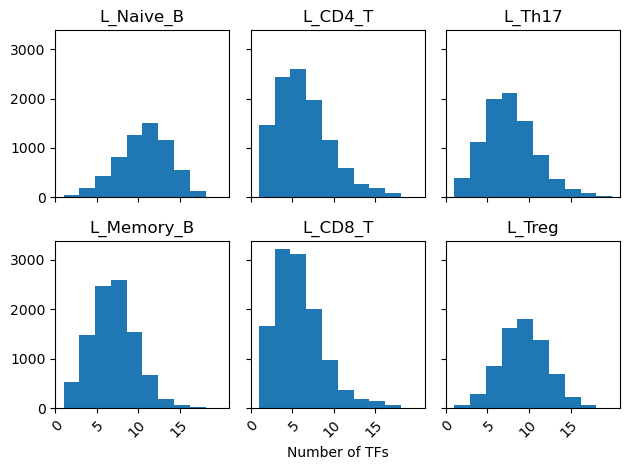

In [14]:
make_group_hist(d_regs, "Number of TFs", range(0, 20, 5))

#### Sparsity=0.01

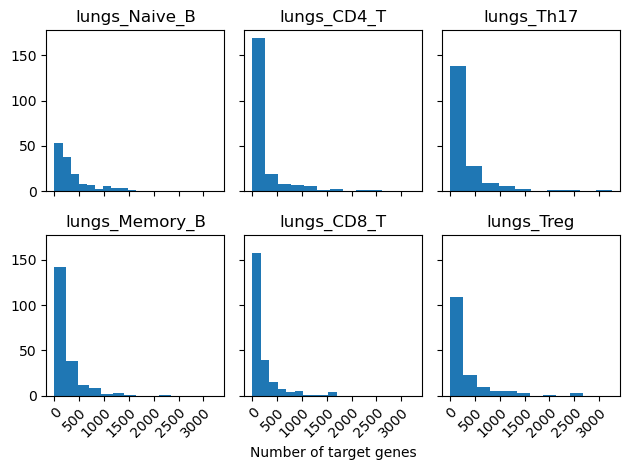

In [27]:
make_group_hist(d_targets, "Number of target genes", range(0, 3500, 500))

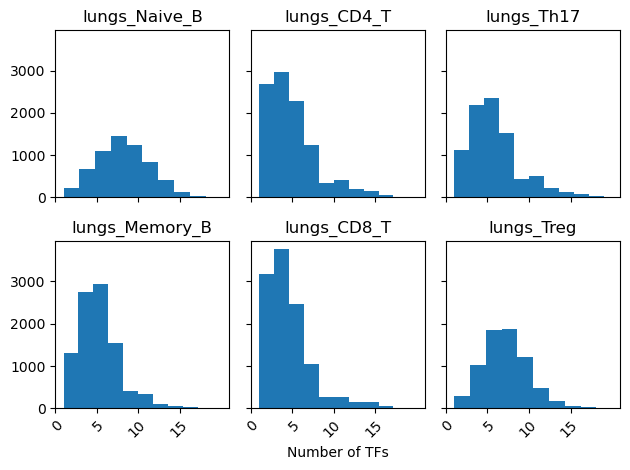

In [29]:
make_group_hist(d_regs, "Number of TFs", range(0, 20, 5))

#### Sparsity=0.015

In [16]:
ct_order=["Naive_B", "Memory_B", "CD4_T", "CD8_T", "Th17", "Treg"]
d_edges={}
for c in ct_order:
    d_edges[f"lungs_{c}"]=retrieve_edges_GRNs(f"lungs_{c}", sparsity_value=0.015)

d_targets={}
d_regs={}
for c in d_edges.keys():
    target_sets=d_edges[c].groupby("Regulator", group_keys=True)[["Target"]].apply(lambda x: set(x.iloc[:,0]))
    d_targets[c]=np.array([len(i) for i in target_sets])
    reg_sets=d_edges[c].groupby("Target", group_keys=True)[["Regulator"]].apply(lambda x: set(x.iloc[:,0]))
    d_regs[c]=np.array([len(i) for i in reg_sets])

In [4]:
make_group_hist(d_regs, "Number of TFs", range(1, 20, 5))

NameError: name 'd_regs' is not defined

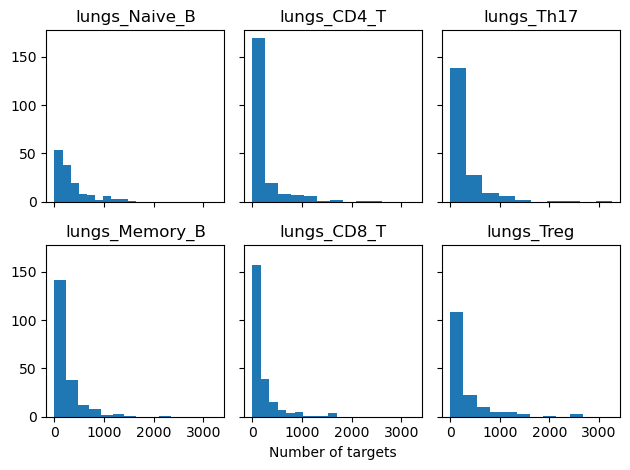

In [18]:
make_group_hist(d_targets, "Number of targets")

With higher sparsity, we see number of TFs that target each gene shifts to on average 5 TFs per gene.  

### Median target genes per TF or Mean TFs that regulate per gene

In [73]:
ct_order=["Naive_B", "Memory_B", "NK", "CD8_T", "CD4_T", "Treg"]
TF_output=pd.DataFrame()
for c in ct_order:
    print(c)
    TF_counts = []
    for s in np.arange(0.005, 0.026, 0.005):
        edges=retrieve_edges_GRNs(f"L_{c}", sparsity_value = s)
        #edges = edges[edges["Strength"] > 0] #retain positive links
        target_sets=edges.groupby("Target", group_keys=True)[["Regulator"]].apply(lambda x: set(x.iloc[:,0]))
        regulator_sets = edges.groupby("Regulator", group_keys=True)[["Target"]].apply(lambda x: set(x.iloc[:,0]))
        TF_counts.append((np.median(np.array([len(i) for i in target_sets])),
                          np.median(np.array([len(i) for i in regulator_sets]))))

    countDF=pd.DataFrame({"cell_states": c,
                          "sparsity": np.arange(0.005, 0.026, 0.005),
                          "median_TF_counts":
                          [round(i[0],1) for i in TF_counts],
                          "median_gene_counts":
                          [round(i[1],1) for i in TF_counts] 
                        })
    TF_output = pd.concat([TF_output, countDF])

Naive_B
Memory_B
NK
CD8_T


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7efd1cc06760>>
Traceback (most recent call last):
  File "/scratch/midway2/jinggu/env/dictys2/lib/python3.9/site-packages/ipykernel/ipkernel.py", line 781, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


CD4_T
Treg


In [72]:
TF_output

,cell_states,sparsity,median_TF_counts,median_gene_counts
0,Naive_B,0.005,3.0,29.0
1,Naive_B,0.010,6.0,86.5
2,Naive_B,0.015,9.0,192.0
3,Naive_B,0.020,12.0,325.0
4,Naive_B,0.025,15.0,459.0
0,Memory_B,0.005,2.0,17.0
1,Memory_B,0.010,4.0,56.0
2,Memory_B,0.015,6.0,119.0
3,Memory_B,0.020,9.0,186.0
4,Memory_B,0.025,11.0,270.5


In [71]:
TF_output.to_csv("../../output/lung_GRN_sparsity_sensitivity.txt")

In [26]:
pos_TF_counts=[]
neg_TF_counts=[]
for c in ct_order:
    edges=retrieve_edges_GRNs(f"L_{c}", sparsity_value = 0.02)
    pos_edges=edges.loc[edges["Strength"]>0, ]
    neg_edges=edges.loc[edges["Strength"]<0, ]
    target_pos_sets=pos_edges.groupby("Target", group_keys=True)[["Regulator"]].apply(lambda x: set(x.iloc[:,0]))
    target_neg_sets=neg_edges.groupby("Target", group_keys=True)[["Regulator"]].apply(lambda x: set(x.iloc[:,0]))
    pos_TF_counts.append(np.median(np.array([len(i) for i in target_pos_sets])))
    neg_TF_counts.append(np.median(np.array([len(i) for i in target_neg_sets])))

tf_counts=pd.DataFrame({"cell_states":ct_order*2,
                        "median_TF_counts":
                        [round(i,1) for i in pos_TF_counts]+[round(i,1) for i in neg_TF_counts],
                        "direction": ["positive"]*len(pos_TF_counts) + 
                                     ["negative"]*len(neg_TF_counts)})
tf_counts

,cell_states,median_TF_counts,direction
0,Naive_B,6.0,positive
1,Memory_B,3.0,positive
2,CD4_T,3.0,positive
3,CD8_T,3.0,positive
4,Th17,4.0,positive
5,Treg,5.0,positive
6,Naive_B,5.0,negative
7,Memory_B,4.0,negative
8,CD4_T,3.0,negative
9,CD8_T,2.0,negative


[Text(0, 0.5, 'Median number of TFs per gene')]

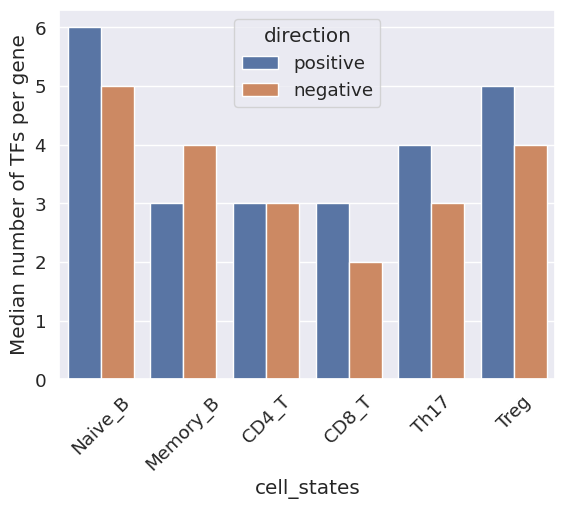

In [24]:
sns.set(font_scale=1.2)
ct_order=["Naive_B", "Memory_B", "CD4_T", "CD8_T", "Th17", "Treg"]
plot = sns.barplot(tf_counts, x="cell_states", y="median_TF_counts",
                  hue="direction", order=ct_order)
plot.set_xticks(ticks=plot.get_xticks(), labels=plot.get_xticklabels(),
                rotation=45)
plot.set(ylabel='Median number of TFs per gene')

In [36]:
pos_TF_counts=[]
neg_TF_counts=[]
for c in ct_order:
    edges=retrieve_edges_GRNs(f"L_{c}", sparsity_value=0.02)
    pos_edges=edges.loc[edges["Strength"]>0, ]
    neg_edges=edges.loc[edges["Strength"]<0, ]
    target_pos_sets=pos_edges.groupby("Regulator", group_keys=True)[["Target"]].apply(lambda x: set(x.iloc[:,0]))
    target_neg_sets=neg_edges.groupby("Regulator", group_keys=True)[["Target"]].apply(lambda x: set(x.iloc[:,0]))
    pos_TF_counts.append(np.median(np.array([len(i) for i in target_pos_sets])))
    neg_TF_counts.append(np.median(np.array([len(i) for i in target_neg_sets])))

tf_counts=pd.DataFrame({"cell_states":ct_order*2,
                        "median_target_counts":
                        [round(i,1) for i in pos_TF_counts]+[round(i,1) for i in neg_TF_counts],
                        "direction": ["positive"]*len(pos_TF_counts) + 
                                     ["negative"]*len(neg_TF_counts)})
tf_counts

,cell_states,median_target_counts,direction
0,Naive_B,161.5,positive
1,Memory_B,81.0,positive
2,CD4_T,73.0,positive
3,CD8_T,75.5,positive
4,Th17,99.0,positive
5,Treg,112.0,positive
6,Naive_B,128.5,negative
7,Memory_B,85.0,negative
8,CD4_T,66.5,negative
9,CD8_T,64.0,negative


[Text(0, 0.5, 'Median number of genes per TF')]

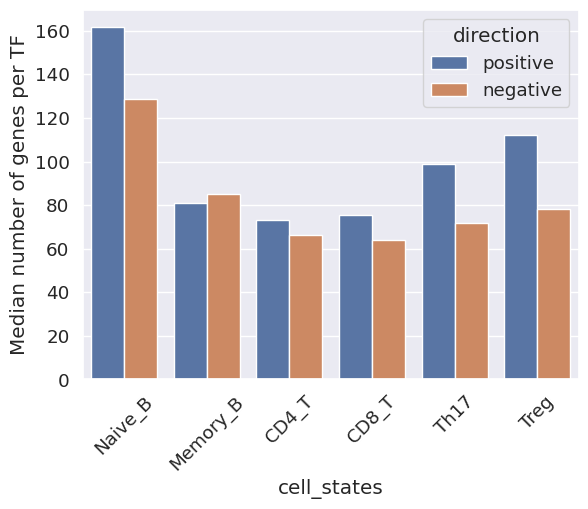

In [28]:
sns.set(font_scale=1.2)
ct_order=["Naive_B", "Memory_B", "CD4_T", "CD8_T", "Th17", "Treg"]
plot = sns.barplot(tf_counts, x="cell_states", y="median_target_counts",
                  hue="direction", order=ct_order)
plot.set_xticks(ticks=plot.get_xticks(), labels=plot.get_xticklabels(),
                rotation=45)
plot.set(ylabel='Median number of genes per TF')

#### Global comparison analyses with regulation markers, expression markers, and differential expression
Combining these regulation markers with expression marker (based on logCPM) and the differential expression results from the [official page](https://cf.10xgenomics.com/samples/cell-arc/2.0.0/pbmc_granulocyte_sorted_10k/pbmc_granulocyte_sorted_10k_web_summary.html), we can annotate each cell subset with their nominated cell types.


In [11]:
# Regulatory dotplot
#Node sizes to draw legend in dot plot
node_size_cpm=[20,50,100,200,500,1000]
#Transformation from CPM to node size
node_size_map_cpm=lambda x:x/5*(x<=100)+(20+(x-100)*500/10/990)*(x>100)

ct_order=[f"lungs_{i}" for i in ["Naive_B", "Memory_B", "CD4_T", "CD8_T", "Th17", "Treg"]]

# prepare input for dotplot
deg,deg_spec,cpm,cpm_spec,regmarker,regmarker_state=compute_spec(d0,nmax=20,vmin=10,ncut=0.25,min_entropy=0.7,
select_state=ct_order)

#specifics for dotplot
deg=deg.loc[:, ct_order]
deg.columns = [i.split("lungs_")[1] for i in ct_order]
deg_spec=deg_spec.loc[:, ct_order]
deg_spec.columns = [i.split("lungs_")[1] for i in ct_order]
fig,ax=dotplot(deg.loc[c(regmarker, "VDR")].iloc[::-1],deg_spec.loc[regmarker].iloc[::-1],size_transform=node_size_map_deg,sizes=np.array(node_size_deg),cmap=cmap)
ax.tick_params(top=True, labeltop=True)

NameError: name 'c' is not defined

In [29]:
deg_spec[deg_spec.index.isin(["SOX4", "BHLHE40", "BACH2", "RUNX2", "PRDM1"])]

,Naive_B,Memory_B,CD4_T,CD8_T,Th17,Treg
BACH2,0.024887,0.312156,0.208322,0.233153,0.134514,0.086969
PRDM1,0.166244,0.060588,0.314768,0.172941,0.259524,0.025936
RUNX2,0.000000,0.265132,0.343577,0.131762,0.241140,0.018389
SOX4,0.541083,0.031372,0.156256,0.152752,0.098702,0.019834


In [80]:
pd.DataFrame({"cell_type": regmarker_state,"marker": regmarker}).to_csv("../output/markerTFs_lung_GRNs_spec1_top20.txt")

In [ ]:
# expression dotplot
deg,deg_spec,cpm,cpm_spec,expmarker,expmarker_state=compute_spec(d0,base='cpm',nmax=10,vmin=50,ncut=0.3,min_entropy=0.7)
#select_state=selected)
cpm=cpm.loc[:, ct_order]
cpm_spec=cpm_spec.loc[:, ct_order]
cpm=deg.loc[:, ct_order]
cpm.columns = [i.split("lungs_")[1] for i in ct_order]
cpm_spec=cpm_spec.loc[:, ct_order]
cpm_spec.columns = [i.split("lungs_")[1] for i in ct_order]

#Node sizes to draw legend in dot plot for expression (CPM)
node_size_cpm=[20,100,500,1000]
#Transformation from target count to node size for regulation
node_size_map_cpm=lambda x:x*(x<=10)+(10+(x-10)*1000/20/990)*(x>10)

#Draw dot plot of expression level and expression specificity with top regulation marker genes
fig2,ax2=dotplot(cpm.loc[regmarker].iloc[::-1],cpm_spec.loc[regmarker].iloc[::-1],size_transform=node_size_map_cpm,sizes=np.array(node_size_cpm),cmap=cmap)
ax2.tick_params(top=True,labeltop=True)

In [18]:
tf_T=pd.read_csv("T_cell_TFs.txt", header=None)
tf_B=pd.read_csv("B_cell_TFs.txt", header=None)

In [8]:
deg,deg_spec,cpm,cpm_spec,regmarker,regmarker_state=compute_spec(d0,nmax=0,vmin=10,ncut=0.25,min_entropy=0.8,
select_state=ct_order)
ct_order=[f"lungs_{i}" for i in ["Naive_B", "Memory_B", "CD4_T", "CD8_T", "Th17", "Treg"]]
deg=deg.loc[:, ct_order]
deg.columns = [i.split("lungs_")[1] for i in ct_order]
deg_spec=deg_spec.loc[:, ct_order]
deg_spec.columns = [i.split("lungs_")[1] for i in ct_order]


NameError: name 'states' is not defined

In [9]:
#Output a list of marker TFs for functional analysis
deg,deg_spec,cpm,cpm_spec,regmarker,regmarker_state=compute_spec(d0,nmax=0,vmin=10,ncut=0.25,min_entropy=0.8,
select_state=ct_order)
pd.DataFrame({"cell_type": regmarker_state, "marker": regmarker}).to_csv("../output/markerTFs_lung_GRNs.txt", index=None)

In [19]:
known_TFs=list(set(regmarker).intersection(set(tf_B.iloc[:,0])))+list(set(regmarker).intersection(set(tf_T.iloc[:,0])))

In [6]:
#Expression markers based on gene expression (by CPM) and its specificity
#Node sizes to draw legend in dot plot
node_size_cpm=[20,50,100,200,500,1000]
#Transformation from CPM to node size
node_size_map_cpm=lambda x:x/5*(x<=100)+(20+(x-100)*500/10/990)*(x>100)
#Find marker genes based on expression specificity through the option base='cpm'
fig,ax=dotplot(deg.loc[known_TFs].iloc[::-1],deg_spec.loc[known_TFs].iloc[::-1],size_transform=node_size_map_deg,sizes=np.array(node_size_deg),cmap=cmap)
ax.tick_params(top=True, labeltop=True)

NameError: name 'known_TFs' is not defined

In [7]:
from matplotlib import ticker
from adjustText import adjust_text
from dictys.net import stat
from dictys.plot import panel

In [ ]:
# Pairwise comparison analyses 
## Retrieve absolute values for regulation activity and expression
pts=np.array([d0.sdict[x] for x in ct_order])
stat1_lcpm=stat.lcpm(d0,cut=0)
stat1_net=stat.net(d0)
stat1_netbin=stat.fbinarize(stat1_net,sparsity=0.01)
stat1_lntarget=stat.flnneighbor(stat1_netbin)
cut_lcpm=np.log2(0+1)
cut_lntarget=np.log2(0+1)

stat1_dlcpm=stat.fmasked(stat1_lcpm, stat1_lcpm>=cut_lcpm,label='log reg_activity')
stat1_dlntarget=stat.fmasked(stat1_lntarget, stat1_lntarget>=cut_lntarget,label='log expression')

ka_default=dict({'s':20,'c':([0.3]*3,),'lw':0,'alpha':0.7})

p=panel.statscatter(ax, pts, 
                    stat1_dlcpm,stat1_dlntarget, 
                    annotate="all",
                    aspect=float(1),lim="min",
                    scatterka=ka_default)

ans_list=p.get_data(p.pts)[0]

d_values={}
for i in range(0, len(ct_order),1):
    ans=ans_list[:,:,i].T
    d_values[ct_order[i].split("lungs_")[1]]=pd.DataFrame(ans,columns=['log2_Expression','log2_RegActivity'],index=p.names)

In [35]:
d_sub_vals={}
for i in d_values.keys():
    d_sub_vals[i]=d_values[i].loc[list(set(known_TFs)),"log2_Expression"]

In [36]:
known_TFs=['SPIB','SPI1','PAX5','EPAS1',
           'SMAD3','LEF1','EOMES',
           'MYB','ASCL2', 'CEBPA', 'EGR2','RUNX2','FOXP3']

<Axes: >

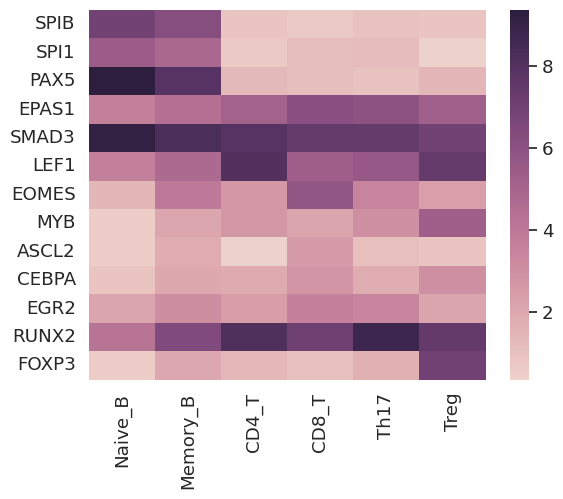

In [37]:
sns.heatmap(pd.DataFrame(d_sub_vals).loc[known_TFs,:], cmap=sns.cubehelix_palette(as_cmap=True))

In [47]:
pd.DataFrame(cpm.index).to_csv("GO_background_genes.txt", index=None, columns=None)

In [ ]:
nodes,edges=fig_subnet(d0,ax,'lungs_CD4_T',regulators=['TCF7'])

In [16]:
edges.loc[edges["Strength"]>0, "Target"].to_csv("ETV7_pos_reg_genes.txt", index=None)

In [ ]:
from dictys.plot.static import fig_subnet
fig=plt.figure(figsize=(10,10))
ax=fig.add_subplot(111)
nodes,edges=fig_subnet(d0,ax,'lungs_CD4_T',regulators=['TCF7'],
                      annotate=list(edges.loc[edges["Strength"]>0, "Target"]) + ['TCF7'])


In [45]:
edges.loc[edges["Strength"]>0, "Target"].to_csv("ASCL2_pos_reg_genes.txt", index=None)

In [29]:
set(d_edges.keys())-set(["Memory_B"])

{'CD4_T', 'CD8_T', 'Naive_B', 'Th17', 'Treg'}

In [27]:
set(["Memory_B"]).difference(set(d_edges.keys()))

set()

In [36]:
bkg_sets=set()
for i in set(d_edges.keys())-set(["CD4_T"]):
    pos_edges=d_edges[i].loc[d_edges[i]["Strength"]>0,:]
    bkg_sets=bkg_sets.union(pos_edges.loc[pos_edges["Regulator"] == "SMAD3", "Target"])

In [37]:
pd.DataFrame(bkg_sets).to_csv("SMAD3_targets_bkg.txt", index=None)

In [95]:
edges.loc[edges["Strength"]>0, "Target"].to_csv("ASCL2_CD8T_target_genes.txt", index=None)

In [147]:
deg,deg_spec,cpm,cpm_spec,regmarker,regmarker_state=compute_spec(d0,nmax=0,vmin=10,ncut=0.25,min_entropy=0.7,
                                                                select_state=states)

In [158]:
markers=set(reg_df.loc[reg_df["regmarker_state"]=="lungs_CD8_T", "regmarker"])
markers

{'ASCL2',
 'BATF3',
 'CEBPA',
 'CPEB1',
 'E2F1',
 'FOXD1',
 'GLIS1',
 'GLIS2',
 'HESX1',
 'HEY2',
 'MAFB',
 'SOX13',
 'TEAD3',
 'TEF'}

In [151]:
markers=set()
for c in list(set(reg_df["regmarker_state"])):
    markers=markers.union(set(reg_df.loc[reg_df["regmarker_state"]==c, "regmarker"]))   

In [162]:
test_set=list(set(reg_df["regmarker_state"]))

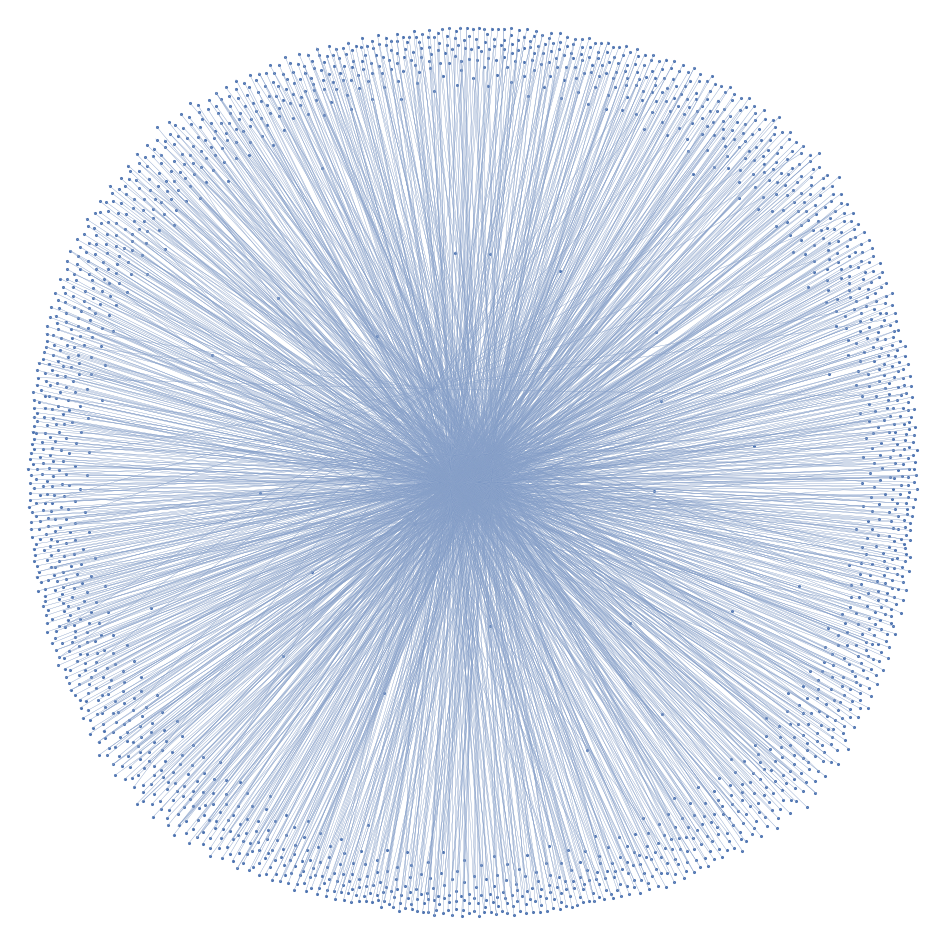

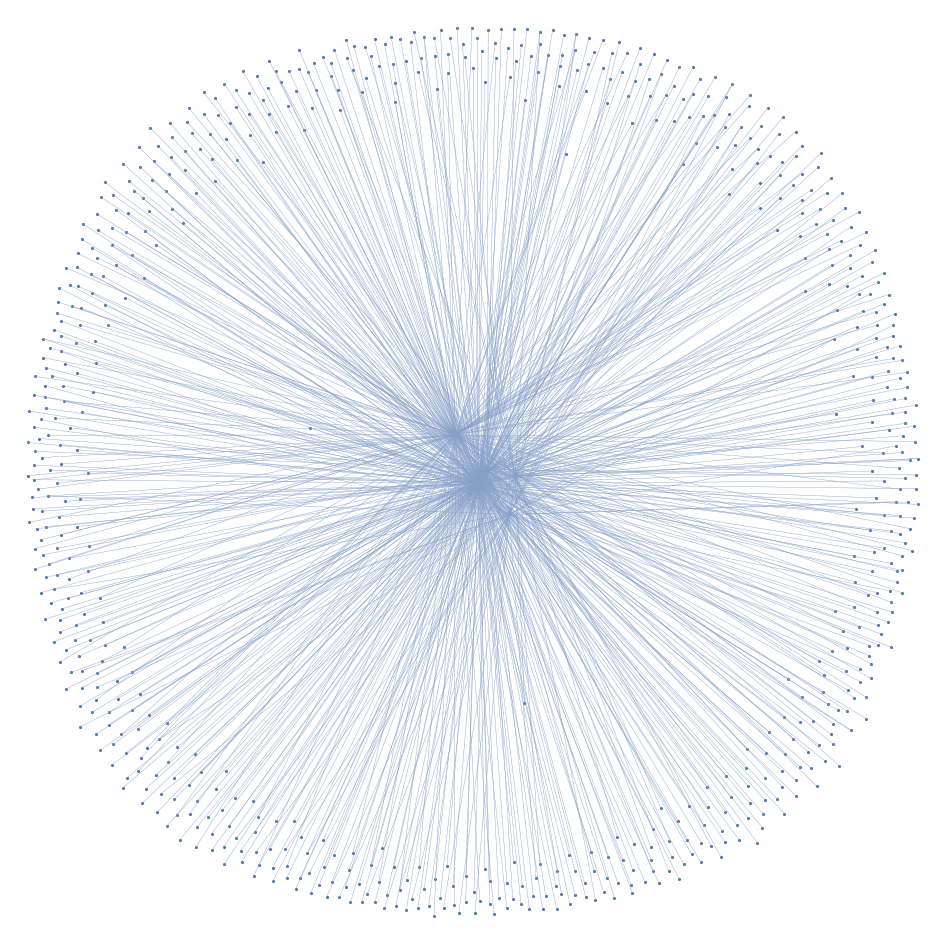

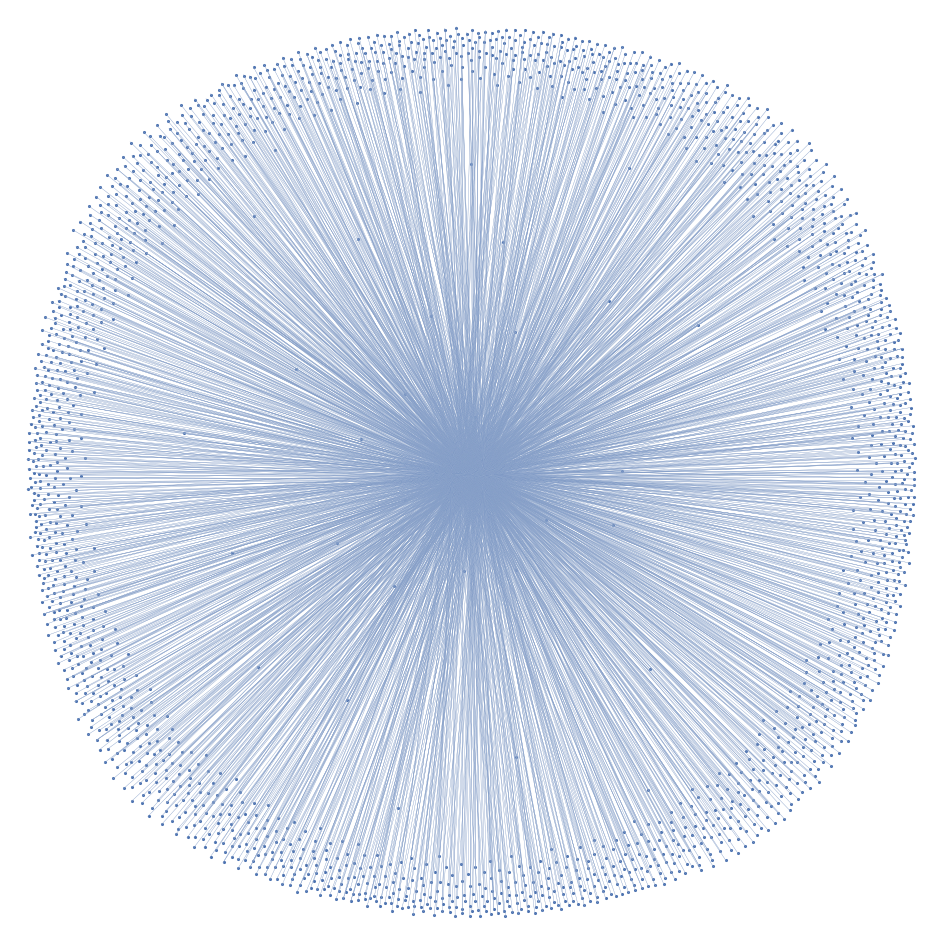

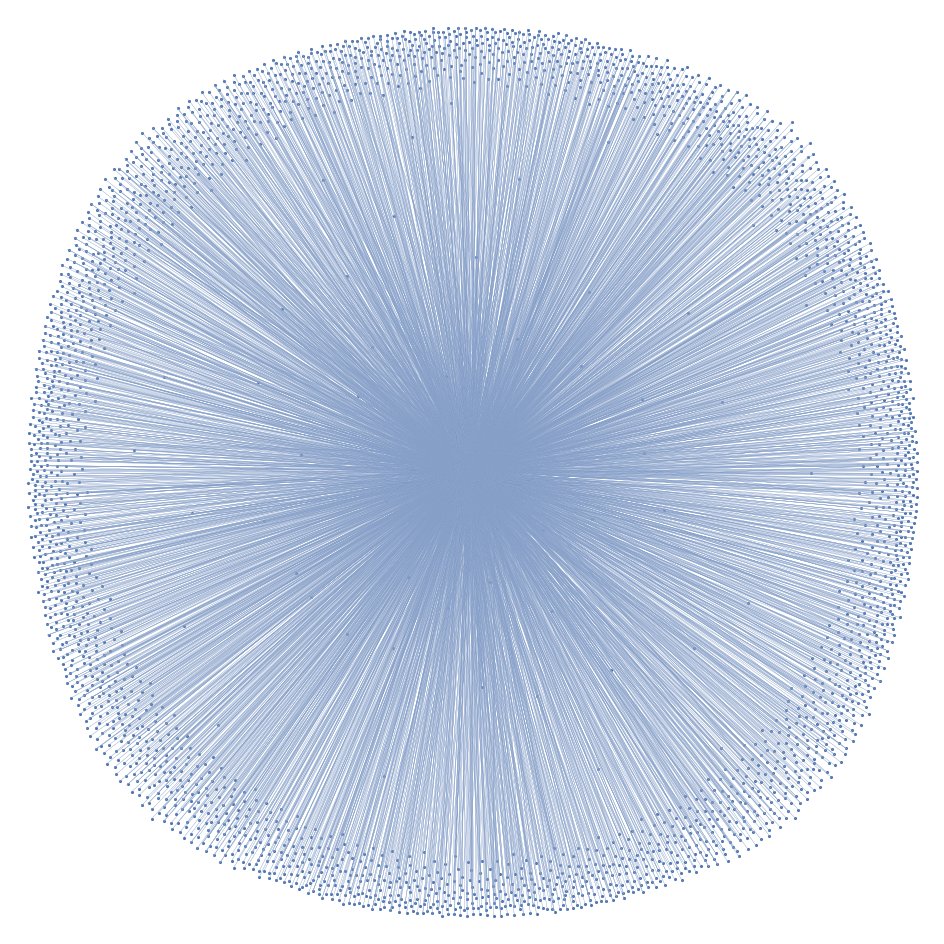

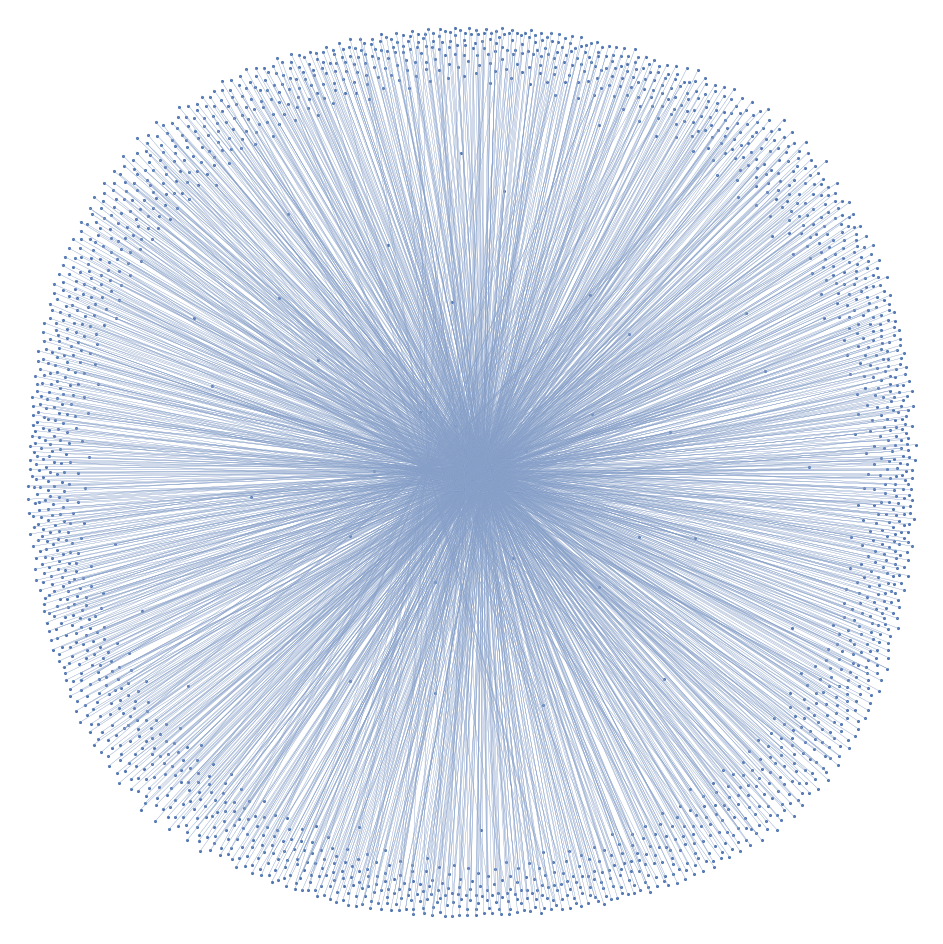

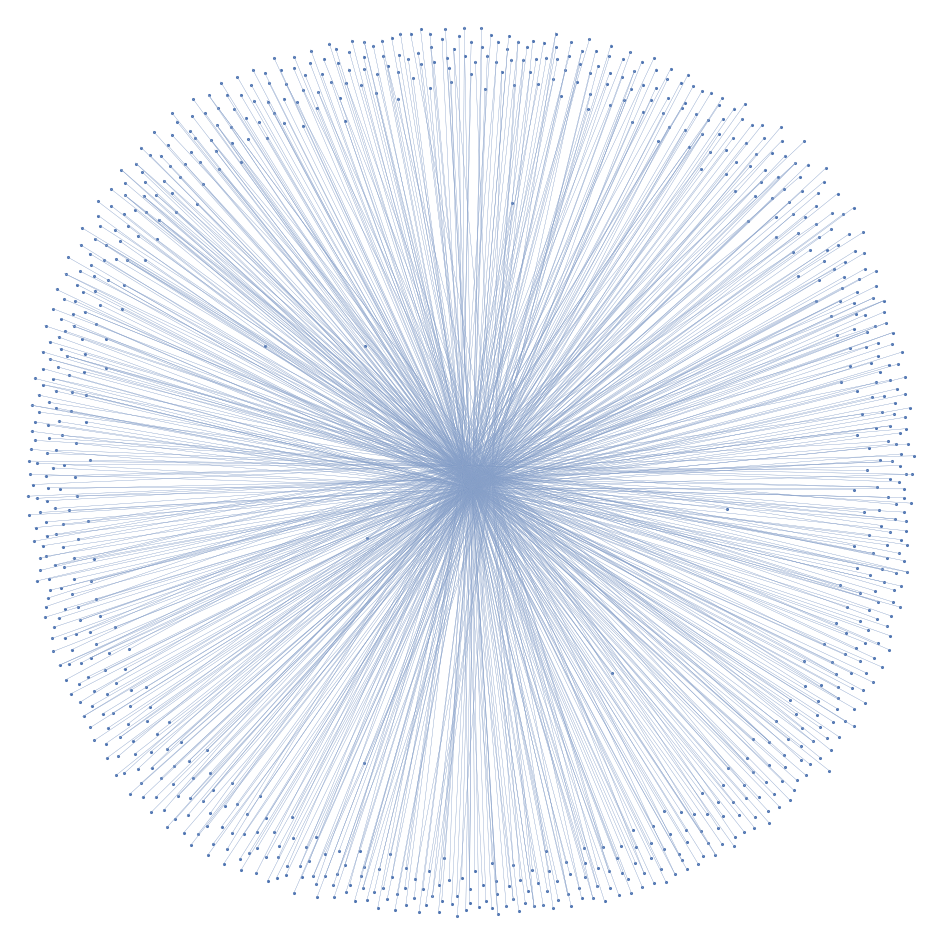

In [159]:
from dictys.plot.static import fig_subnet
d_reg={}
for c in list(set(reg_df["regmarker_state"])):
    fig=plt.figure(figsize=(12,12))
    ax=fig.add_subplot(111)
    markers=set(reg_df.loc[reg_df["regmarker_state"]==c, "regmarker"])
    nodes,edges=fig_subnet(d0,ax,c,regulators=list(markers), sparsity=0.02)
    d_reg[c] = edges

In [161]:
np.save('lungs_specific_TFs_reg_edges.npy', d_reg)

In [164]:
d_pos_reg={}
mean_counts=[]
for c in test_set:
    d_pos_reg[c] = d_reg[c].loc[d_reg[c]["Strength"]>0]
    query=d_pos_reg[c].groupby("Regulator", group_keys=True)[["Target"]].apply(lambda x: set(x.iloc[:,0]))
    #mean number of enhancer TF target genes across cell types
    mean_counts.append(np.mean([len(i) for i in query]))

In [174]:
[i.split("lungs_")[1] for i in test_set]

['CD8_T', 'CD4_T', 'Th17', 'Naive_B', 'Memory_B', 'Treg']

In [38]:
def get_percent_overlaps(d, cell_type):
    query=d[cell_type].groupby("Regulator", group_keys=True)[["Target"]].apply(lambda x: set(x.iloc[:,0]))
    d_overlaps={}
    for i in query.index:
        d_overlaps[i]=[]
        for j in query.index:
            d_overlaps[i].append(round(len(query[i].intersection(query[j]))/len(query[i]), 2))
    overlaps=pd.DataFrame(d_overlaps, index=list(query.index))
    return(overlaps)

<Axes: >

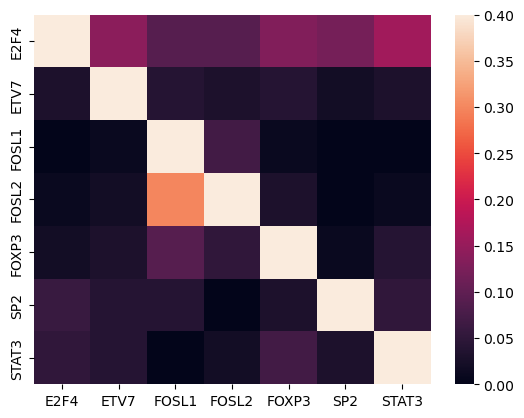

In [39]:
tf_sharing=get_percent_overlaps(d_pos_reg, "lungs_Regulatory_T_cells")
sns.heatmap(tf_sharing, vmax=0.4)

<Axes: >

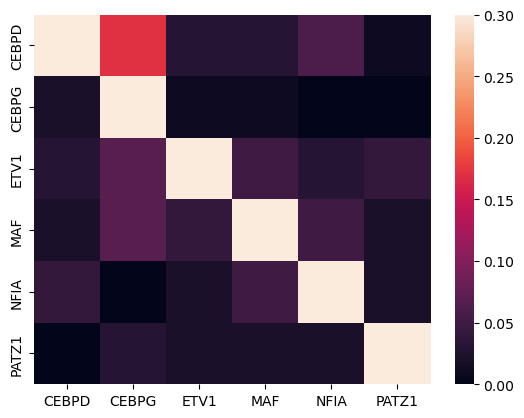

In [40]:
tf_sharing=get_percent_overlaps(d_pos_reg, "lungs_Type_17_helper_T_cells")
sns.heatmap(tf_sharing, vmax=0.3)

<Axes: >

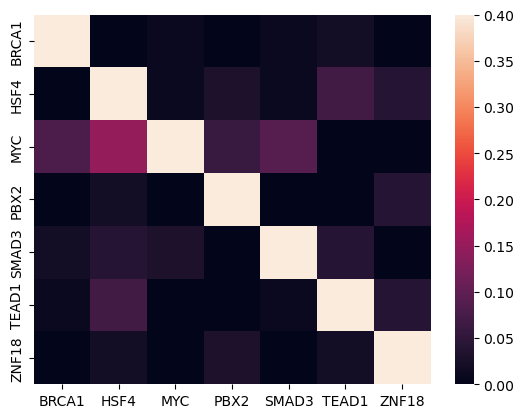

In [41]:
tf_sharing=get_percent_overlaps(d_pos_reg, "lungs_Tcm_Naive_helper_T_cells")
sns.heatmap(tf_sharing, vmax=0.4)

<Axes: >

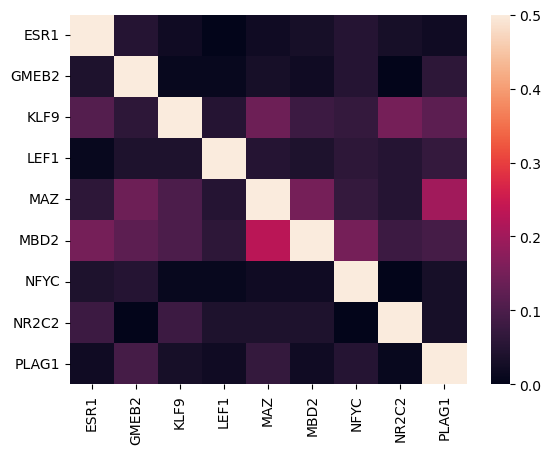

In [42]:
tf_sharing=get_percent_overlaps(d_pos_reg, "spleens_Tcm_Naive_helper_T_cells")
sns.heatmap(tf_sharing, vmax=0.5)

<Axes: >

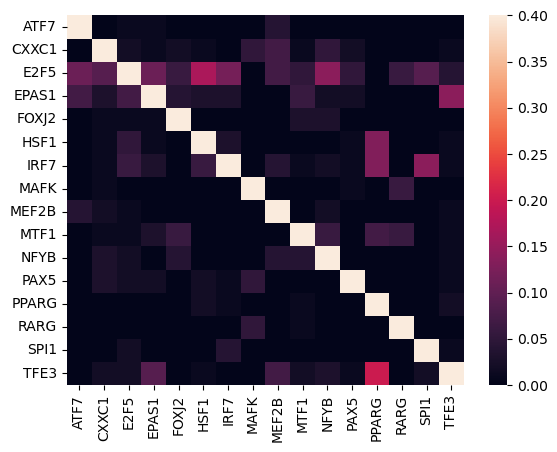

In [120]:
tf_sharing=get_percent_overlaps(d_pos_reg, "lungs_Memory_B_cells")
sns.heatmap(tf_sharing, vmax=0.4)

In [101]:
union_set=query["FOXJ2"]
for i in ["IRF7", "MEF2B"]:
    union_set.union(union_set, query[i])

In [91]:
query=d_reg["lungs_Memory_B_cells"].groupby("Regulator", group_keys=True)[["Target"]].apply(lambda x: set(x.iloc[:,0]))
set1=query["FOXJ2"].intersection(query["IRF7"])
set2=query["IRF7"].intersection(query["MEF2B"])
set3=query["FOXJ2"].intersection(query["MEF2B"])


In [103]:
pd.DataFrame(union_set).to_csv("FOXJ2_MEF2B_IRF7_sharing_genes.txt", index=None, columns=None)

In [96]:
pd.DataFrame(set1).to_csv("FOXJ2_IRF7_sharing_genes.txt", index=None, columns=None)
pd.DataFrame(set2).to_csv("MEF2B_IRF7_sharing_genes.txt", index=None, columns=None)
pd.DataFrame(set3).to_csv("FOXJ2_MEF2B_sharing_genes.txt", index=None, columns=None)


<Axes: >

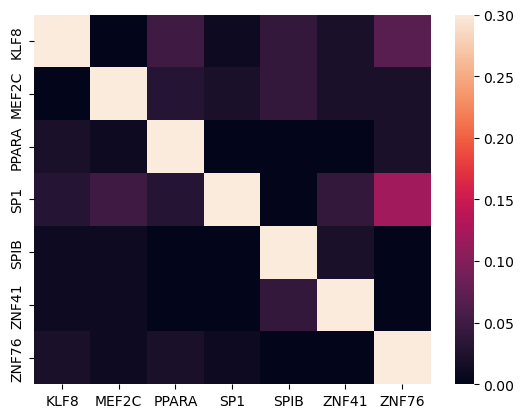

In [119]:
tf_sharing=get_percent_overlaps(d_pos_reg, "spleens_Naive_B_cells")
sns.heatmap(tf_sharing, vmax=0.3)

<Axes: >

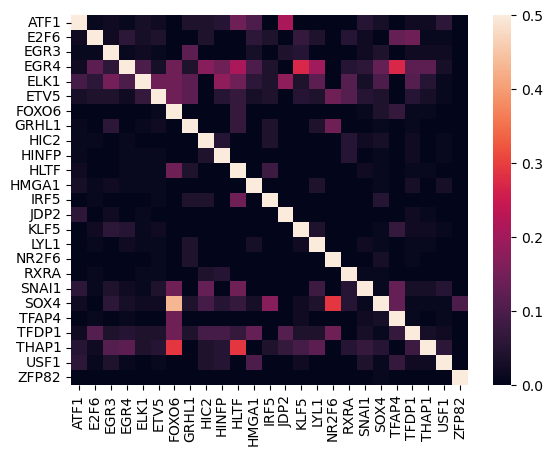

In [118]:
tf_sharing=get_percent_overlaps(d_pos_reg, "spleens_Memory_B_cells")
sns.heatmap(tf_sharing, vmax=0.5)

In [ ]:
query=d["spleens_Memory_B_cells"].groupby("Regulator", group_keys=True)[["Target"]].apply(lambda x: set(x.iloc[:,0]))


## 6. Relate to Asthma

In [4]:
# retrieve_edges_GRNs
from functools import partial
import numpy as np
from dictys.net.layout import _fruchterman_reingold
from dictys.net import stat

def retrieve_edges_GRNs(state, sparsity_value=0.01):
    pts=np.array([d0.sdict[state]])
    stat1_net=stat.net(d0)
    stat1_netbin=stat.fbinarize(stat1_net,sparsity=sparsity_value)
    #Subnetwork
    stat1_subnet,stat1_subnetbin=stat1_net,stat1_netbin
    transformation=lambda x:x
    stat1_subnet_trunc=stat.function(lambda *x:transformation(x[0]*x[1]),
                                     [stat1_subnet,stat1_subnetbin],
                                     names=stat1_subnet.names)
    edges=stat1_subnet_trunc.compute(pts)[:,:,0]
    t1=np.nonzero(edges)
    edges=pd.DataFrame([stat1_subnet_trunc.names[0][t1[0]],
                        stat1_subnet_trunc.names[1][t1[1]],
                        edges[t1[0],t1[1]]],index=['Regulator','Target','Strength']).T
    return(edges)

### Identify targets common across TFs

In [5]:
ct_order=[f"L_{i}" for i in ["Naive_B", "Memory_B", "NK", "CD8_T", "CD4_T", "Treg"]]
lung_grns = {}
for ct in ct_order:
    lung_grns[ct] = retrieve_edges_GRNs(ct)

In [56]:
all_regs = []
for ct in ct_order:
    common_targets = lung_grns[ct][lung_grns[ct]["Strength"] >0]["Target"]
    all_regs.append(list(common_targets))

In [60]:
#from functools import reduce
pd.DataFrame(reduce(np.intersect1d, all_regs)).to_csv("../output/dictys/asthma_TFs/common_TF_targets.txt",
                                                     index = None)

### Global comparison for Asthma TFs

In [75]:
aoa_genes=pd.read_csv("/home/jinggu/cluster/projects/u19_multiomics/data/aoa_candidate_genes.txt", sep="\t")
set(aoa_genes["gene"])

{'BACH2',
 'D2HGDH',
 'GAL3ST2',
 'GATA3',
 'HDAC7',
 'IL13',
 'IRF1',
 'NAB2',
 'PTPRC',
 'RPS26',
 'SMAD3',
 'TSLP',
 'ZBTB10',
 'ZEB2'}

In [78]:
#deg,deg_spec,cpm,cpm_spec,regmarker,regmarker_state=compute_spec(d0,nmax=0,vmin=10,ncut=0.25,min_entropy=1, )
f_aoa=pd.read_csv("/home/jinggu/cluster/projects/u19_multiomics/data/aoa_candidate_genes.txt", sep="\t")
aoa_genes=set(f_aoa["gene"])
aoa_genes.intersection(regmarker)

f_coa=pd.read_csv("/home/jinggu/cluster/projects/u19_multiomics/data/coa_candidate_genes.txt", sep="\t")
coa_genes=set(f_coa["gene"])
coa_genes.intersection(regmarker)

asthma_TFs = aoa_genes.union(coa_genes).union({'SPIB','PRDM4','EOMES','RUNX3','FOXP3','BATF','RORA','STAT3'})

asthma_TFs=asthma_TFs.intersection(deg.index)
# tsuo2022=pd.read_csv("../data/Tsuo2022_meta_analysis_asthma_risk_genes.csv", skiprows=3)
# asthma_risk_genes=tsuo2022["SYMBOL"][~pd.isnull(tsuo2022["SYMBOL"])]
# asthma_genes=asthma_risk_genes.union(aoa_genes.union(coa_genes))
# asthma_TFs=asthma_genes.intersection(deg.index)

In [79]:
aoa_genes.union(coa_genes).intersection(deg.index)

{'BACH2', 'CEBPA', 'GATA3', 'IRF1', 'SMAD3', 'TBX21', 'TCF7'}

In [4]:
tsuo2022 = pd.read_csv("../data/Tsuo2022_meta_analysis_asthma_risk_genes.csv", skiprows=3)

In [7]:
asthma_risk_genes=tsuo2022["SYMBOL"][~pd.isnull(tsuo2022["SYMBOL"])]
asthma_risk_genes

0         IL6R
1       IL1RL1
2       IL18R1
3      IL18RAP
4       SLC9A4
        ...   
592    SLC10A3
593      FAM3A
594       G6PD
595     CTAG1A
596     CTAG1B
Name: SYMBOL, Length: 590, dtype: object

In [25]:
asthma_risk_genes=tsuo2022["SYMBOL"][~pd.isnull(tsuo2022["SYMBOL"])]
asthma_genes=set(asthma_risk_genes).union(aoa_genes.union(coa_genes))
asthma_TFs=asthma_genes.intersection(deg.index)

In [26]:
asthma_TFs

{'BACH2',
 'BCL6',
 'CEBPA',
 'FOXP1',
 'GATA3',
 'GMEB2',
 'IRF1',
 'NR1D1',
 'PBX2',
 'PPARG',
 'RORA',
 'RUNX3',
 'SMAD3',
 'SRF',
 'STAT6',
 'TBX21',
 'TCF7',
 'TEF',
 'ZNF76'}

In [3]:
ct_order=[f"lungs_{i}" for i in ["Naive_B", "Memory_B", "CD4_T", "CD8_T", "Th17", "Treg"]]
lung_grns = {}
for ct in ct_order:
    lung_grns[ct] = retrieve_edges_GRNs(ct, sparsity_value=0.02)

In [171]:
asthma_tf_targets = {}
for ct in ct_order:
    net = lung_grns[ct][lung_grns[ct]["Strength"] > 0]
    tf_net = net[net["Regulator"].isin(asthma_TFs)].sort_values(by='Strength', ascending=False)
    asthma_tf_targets[ct] = set(tf_net["Target"][0:100])
    

In [172]:
for i in asthma_tf_targets.keys():
    pd.DataFrame(asthma_tf_targets[i]).to_csv(f"../output/dictys/{i}_asthma_TF_targets.txt", index=None, header=None)

In [154]:
net[net["Regulator"].isin(asthma_TFs)].sort_values(by='Strength', ascending=False)

,Regulator,Target,Strength
25836,PPARG,ELF1,1.084143
26577,RUNX3,TGIF1,0.651071
14495,IRF1,RPL24,0.643816
14477,IRF1,PREX1,0.593443
14408,IRF1,ETV6,0.580574
...,...,...,...
14447,IRF1,MRPS28,0.135532
12256,FOXP1,CYTIP,0.135478
25515,PBX2,PREPL,0.135343
14476,IRF1,PPP1R11,0.135299


In [9]:
reg_df=pd.DataFrame({"regmarker":regmarker,
         "regmarker_state":regmarker_state})

In [10]:
for i in list(set(coa_genes).intersection(regmarker)):
    print(reg_df.loc[reg_df["regmarker"]==i])

   regmarker regmarker_state
47      TCF7     lungs_CD4_T
   regmarker regmarker_state
42     SMAD3     lungs_CD4_T
   regmarker regmarker_state
60     CEBPA     lungs_CD8_T


In [30]:
# Asthma riks genes from Ethan's paper
#asthma_TFs=['SPIB', 'PRDM4','RUNX3', 'EOMES','RORA','FOXP3','BACH2', 'CEBPA', 'GATA3', 'IRF1', 'SMAD3', 'TBX21', 'TCF7']
# Asthma risk genes from Tsuo2022 + Ethan's paper
asthma_TFs = ['SPIB', 'PRDM4','RUNX3', 'EOMES','RORA','FOXP3'] + list(asthma_TFs)


<Figure size 640x480 with 0 Axes>

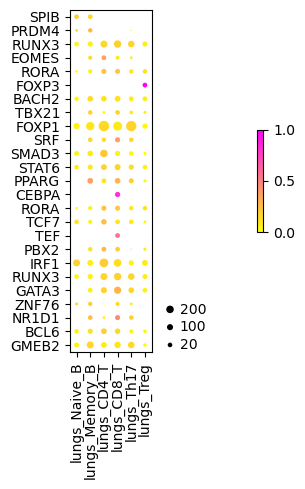

In [31]:
node_size_deg=[20,100,200]
#Transformation from target count to node size
node_size_map_deg=lambda x:x*(x<=10)+(10+(x-10)*500/10/490)*(x>10)

#Find marker genes based on regulatory activity specificity
#Arguments control how many top markers to show and the cutoffs for target count, its specificity at the most abundant cell subset, and its entropy over all cell subsets
deg,deg_spec,cpm,cpm_spec,regmarker,regmarker_state=compute_spec(d0,nmax=0,vmin=10,ncut=0.25,min_entropy=0.7, sparsity=0.015)

#Expression markers based on gene expression (by CPM) and its specificity
ct_order=["Naive_B", "Memory_B", "CD4_T", "CD8_T", "Th17", "Treg"]
#Find marker genes based on expression specificity through the option base='cpm'
full_order=[f"lungs_{i}" for i in ct_order] #+ [f"spleens_{i}" for i in ct_order]
plt.figure()
fig,ax=dotplot(deg.loc[asthma_TFs,full_order].iloc[::-1],
               deg_spec.loc[asthma_TFs, full_order].iloc[::-1],
               size_transform=node_size_map_deg,sizes=np.array(node_size_deg),cmap=cmap)


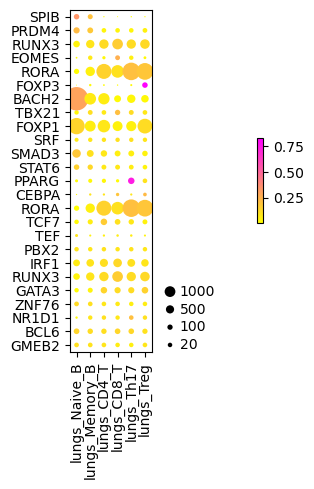

In [32]:
#Redraw of expression marker plot
deg,deg_spec,cpm,cpm_spec,expmarker,expmarker_state=compute_spec(d0,base='cpm',nmax=10,vmin=50,ncut=0.3,min_entropy=0.7)
#select_state=selected)
# cpm=cpm.loc[:, new_cols]
# cpm_spec=cpm_spec.loc[:, new_cols]
# cpm=deg.loc[:, ct_order]
# cpm.columns = [i.split("lungs_")[1] for i in ct_order]
# cpm_spec=cpm_spec.loc[:, ct_order]
# cpm_spec.columns = [i.split("lungs_")[1] for i in ct_order]

#Node sizes to draw legend in dot plot for expression (CPM)
node_size_cpm=[20,100,500,1000]
#Transformation from target count to node size for regulation
node_size_map_cpm=lambda x:x*(x<=10)+(10+(x-10)*1000/20/990)*(x>10)

#Draw dot plot of expression level and expression specificity with top regulation marker genes
fig2,ax2=dotplot(cpm.loc[list(asthma_TFs),full_order].iloc[::-1],
                 cpm_spec.loc[list(asthma_TFs), full_order].iloc[::-1],size_transform=node_size_map_cpm,sizes=np.array(node_size_cpm),cmap=cmap)
#ax2.tick_params(top=True,labeltop=True)

### Heatmap of top target genes of select TFs in their corresponding cell types
Then we move on to investigate select regulation marker TFs. Their top target genes (by regulation strength) in the corresponding cell type may indicate their functional programs.


In [20]:
annot_genes = "CTLA4,HSPD1,PIK3CG,PRKCQ,PRNP,PTPN22,PTPRC,RARA,RPS6,SP3,TBX21,TNFSF14,VAV1,XBP1,JAK2".split(',')
annot_genes

['CTLA4',
 'HSPD1',
 'PIK3CG',
 'PRKCQ',
 'PRNP',
 'PTPN22',
 'PTPRC',
 'RARA',
 'RPS6',
 'SP3',
 'TBX21',
 'TNFSF14',
 'VAV1',
 'XBP1',
 'JAK2']

In [11]:
tf=['STAT6']
#tf= ['PPARG', 'PBX2', 'NR1D1']
tf_sets = []
for i in tf:
    for j in [f"L_{x}" for x in ct_order]:
        if deg[deg.index==i][j].any(): #check if any or more element are non-zero
            tf_sets.append((i, j))

In [45]:
net.to_csv("STAT6_top10_targets_across_cell_types.csv")

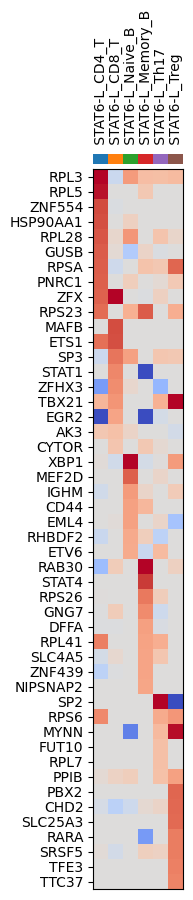

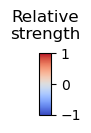

In [44]:
from dictys.plot.static import fig_heatmap_top
#Number of top targets for each TF
ntop=10
#Searching for top activated target genes only
direction=1
annot_genes = "CTLA4,HSPD1,PIK3CG,PRKCQ,PRNP,PTPN22,PTPRC,RARA,RPS6,SP3,TBX21,TNFSF14,VAV1,XBP1,JAK2".split(',')
fig,fig_colorbar,net=fig_heatmap_top(d0,tf_sets,ntop=ntop,
                                     direction=direction,aspect=1,gann="all")

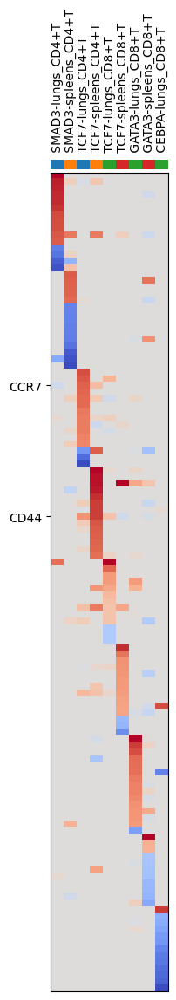

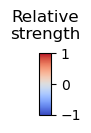

In [47]:
#Only annotating select target genes
#Target genes to annotate
gann='CD69,ITGA1,ITGAE,KLF2,EOMES,TBX21,CCR7,CD44,SELL,TGFB,BLIMP1,CXCR5,S1PR1,KLRG1,CCR5,CXCR3,CXCR6,CREM,VPS37B,RORA,RAMP3,TNFRSF18'.split(',')
#Aspect ratio
aspect=0.5

fig,fig_colorbar,net=fig_heatmap_top(d0,tf,ntop=ntop,direction=direction,gann=gann,aspect=aspect)


## 7. Link chromatin activity with transcription under specific context

### Differential regulation & differential expression analyses between two cell types
From the above global-level analyses, we zoom in for two cell types to understand the differences in their programs. Lacking a HSC population, here we compare T regs and B cells as an example.

Differential expression logFC is the log Fold Change in expression level (CPM+1). Differential regulation logFC is the log Fold Change in regulatory activity (target count+1). They each may highlight different genes for further investigations. So we plot these two axes together to understand their differences and similarities, and to inform downstream analyses.

In [47]:
select_state = 'Naive_B,Memory_B,NK,CD8_T,CD4_T,Treg'.split(',')
grn_path = "../../output/output_dir/remove_dup/dictys"
for i in np.round(np.arange(0.01, 0.036, 0.005), 3):
    for j in select_state:
        retrieve_edges_GRNs(state = f"L_{j}", sparsity_value=i).to_csv(f"{grn_path}/sparsity{i}/L_{j}_GRN.txt", index = None)
        if j not in d0.sdict.keys():
            continue
        else:
            retrieve_edges_GRNs(state = f"S_{j}", sparsity_value=i).to_csv(f"{grn_path}/sparsity{i}/S_{j}_GRN.txt", index = None)

In [1]:
from dictys.plot.static import fig_diff_scatter,fig_diff_rank

#Cell type/state names to compare in (reference, alternative) format. Here it is Treg v.s. B.
ct_order=["CD4_T", "CD8_T", "NK", "Naive_B", "Memory_B"]
top_TFs = {}
for i in ct_order:
    for j in np.round(np.arange(0.01, 0.036, 0.005), 3):
        states=(f"S_{i}", f"L_{i}")
        fig=plt.figure()
        ax=fig.add_subplot(111)
        data=fig_diff_scatter(d0,ax,states)
        #Draw figure
        #Number of top genes to annotate on each side
        ntop=5
        #Find genes to annotate
        annotate=np.partition(data.values,[ntop-1,-ntop],axis=0)
        annotate=((data.values<=annotate[ntop-1])|(data.values>=annotate[-ntop])).any(axis=1)
        annotate=list(data.index[annotate])
        top_TFs[i] = annotate
        fig=plt.figure(figsize = (5, 5))
        fig.title(f"{i}: sprasity={j}")
        ax=fig.add_subplot(111)
        data=fig_diff_scatter(d0,ax,states, sparsity = j, annotate=annotate)# aspect = 1, lim = {"min"})
        fig2=fig_diff_rank(data,figsize=(0.02,4),annotate=annotate)
        #data.to_csv(f"{grn_path}/sparsity{j}/{i}_cross_tissue_DE_DR_logFC.txt")

KeyboardInterrupt: 

In [9]:
ct_order=["CD4_T", "CD8_T", "Treg", "NK", "Naive_B", "Memory_B"]
grn_path = "../../output/output_dir/remove_dup/dictys"


/tmp/jobs/48805548/ipykernel_277391/898873606.py:8: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig=plt.figure()


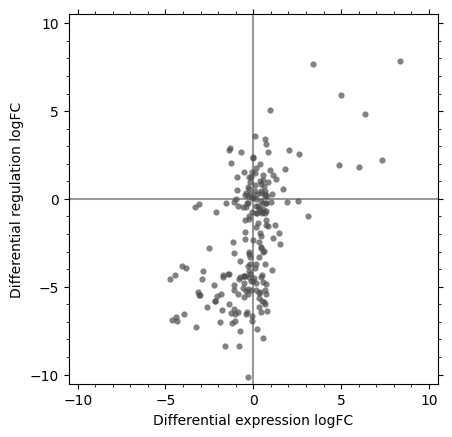

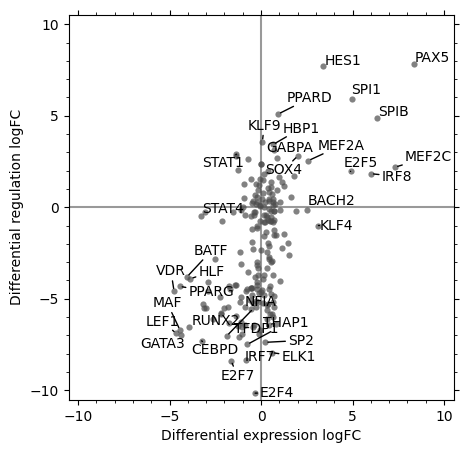

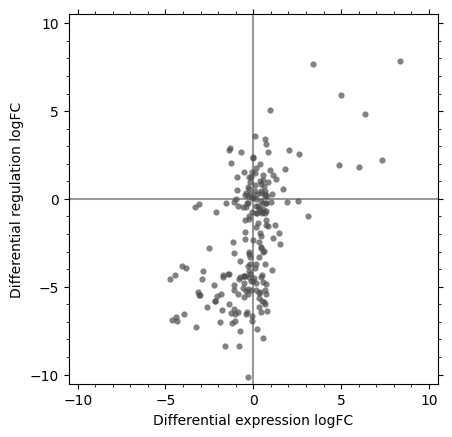

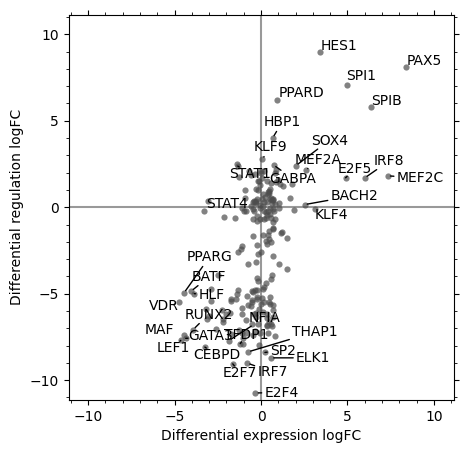

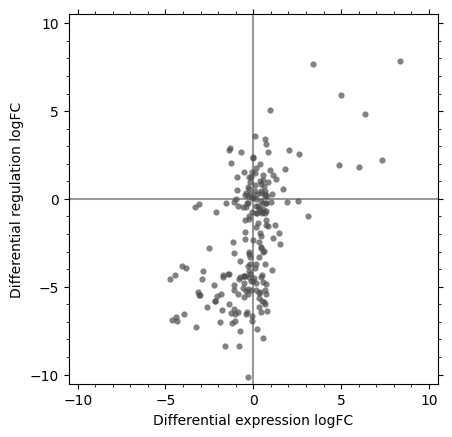

...

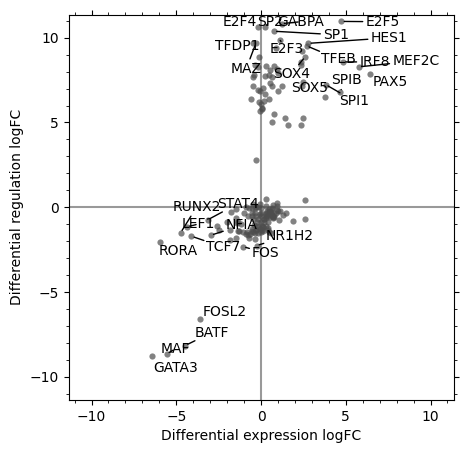

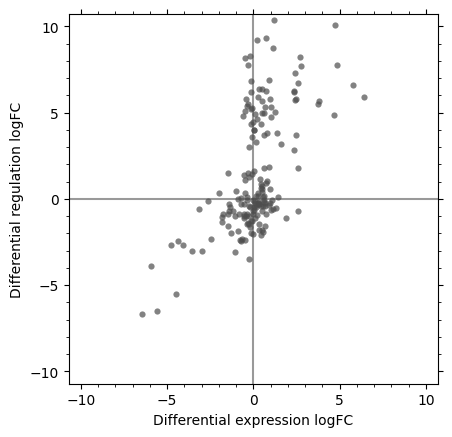

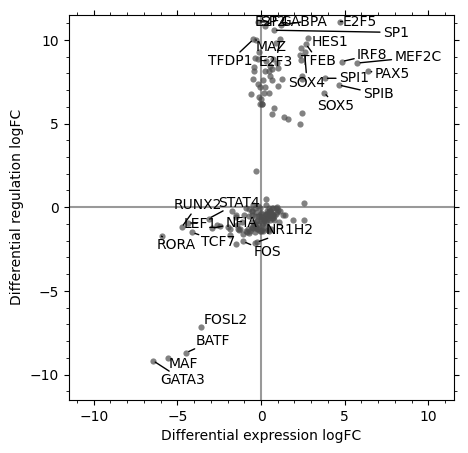

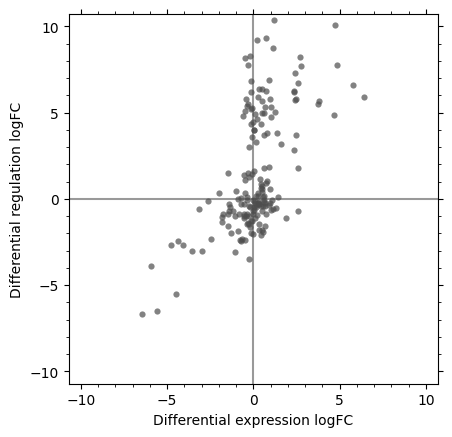

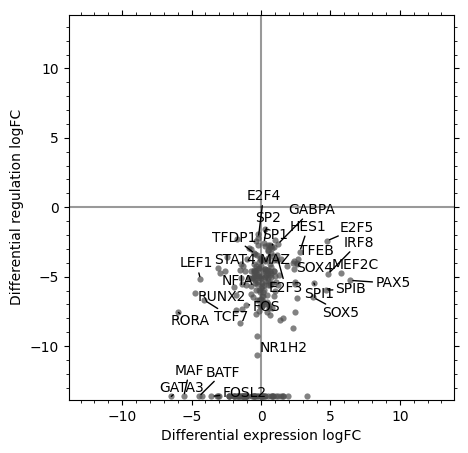

In [14]:
from dictys.plot.static import fig_diff_scatter,fig_diff_rank

#Cell type/state names to compare in (reference, alternative) format. Here it is Treg v.s. B.
top_TFs = {}
for i in ["L", "S"]:#list(range(1, len(ct_order)-1):
    for j in np.round(np.arange(0.01, 0.036, 0.005), 3):
        states=(f"{i}_{ct_order[0]}", f"{i}_{ct_order[4]}")
        fig=plt.figure()
        ax=fig.add_subplot(111)
        data=fig_diff_scatter(d0,ax,states)
        #Draw figure
        #Number of top genes to annotate on each side
        ntop= 10
        #Find genes to annotate
        annotate=np.partition(data.values,[ntop-1,-ntop],axis=0)
        annotate=((data.values<=annotate[ntop-1])|(data.values>=annotate[-ntop])).any(axis=1)
        annotate=list(data.index[annotate])
        top_TFs[i] = annotate
        fig=plt.figure(figsize = (5, 5))
        ax=fig.add_subplot(111)
        data=fig_diff_scatter(d0,ax,states, sparsity = j, annotate=annotate)# aspect = 1, lim = {"min"})
        #fig2=fig_diff_rank(data,figsize=(0.02,4),annotate=annotate)
        data.to_csv(f"{grn_path}/sparsity{j}/{i}_{ct_order[0]}_{ct_order[4]}_DE_DR_logFC.txt")

In [30]:
pd.DataFrame(annotate).to_csv("../output/diffTFs_lung_Th17_vs_CD4T.txt", index=None, header=False)

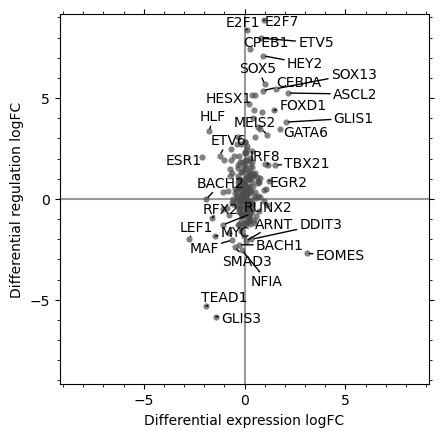

In [11]:
from dictys.plot.static import fig_diff_scatter,fig_diff_rank
#Cell type/state names to compare in (reference, alternative) format. Here it is Treg v.s. B.
states=('L_CD4_T','L_CD8_T')

#fig=plt.figure()
ax=fig.add_subplot(111)
data=fig_diff_scatter(d0,ax,states)

#Draw figure
#Number of top genes to annotate on each side
ntop=10
#Find genes to annotate
annotate=np.partition(data.values,[ntop-1,-ntop],axis=0)
annotate=((data.values<=annotate[ntop-1])|(data.values>=annotate[-ntop])).any(axis=1)
annotate=list(data.index[annotate])
fig=plt.figure()
ax=fig.add_subplot(111)
data=fig_diff_scatter(d0,ax,states, annotate=annotate)
#fig_rank=fig_diff_rank(data,annotate=annotate)

In [60]:
for i in ["CD4_T", "CD8_T", "Memory_B"]:
    deg=pd.read_csv(f"{i}_DEG.csv")
    sig_deg=deg.loc[deg["p_val_adj"]<=0.05].index
    commons=set(cpm.index).intersection(set(sig_deg))
    print(len(set(d_edges[i]["Target"]).intersection(commons))/len(commons))

0.9038461538461539
0.7878787878787878
0.8648648648648649


['spleens_Naive_B_cells', 'spleens_Memory_B_cells']


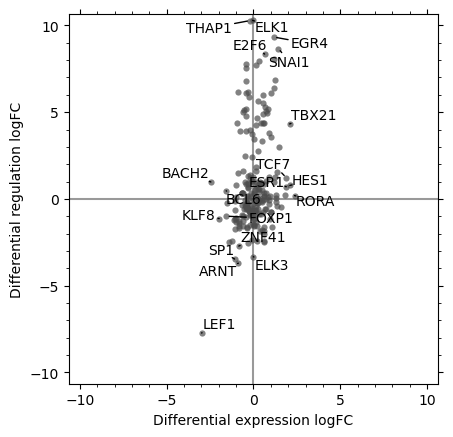

In [58]:
#Cell type/state names to compare in (reference, alternative) format. Here it is Treg v.s. B.
states=[selected[i] for i in [5,7]]
print(states)
#fig=plt.figure()
#ax=fig.add_subplot(111)
data=fig_diff_scatter(d0,ax,states)

#Draw figure
#Number of top genes to annotate on each side
ntop=5
#Find genes to annotate
annotate=np.partition(data.values,[ntop-1,-ntop],axis=0)
annotate=((data.values<=annotate[ntop-1])|(data.values>=annotate[-ntop])).any(axis=1)
annotate=list(data.index[annotate])
fig=plt.figure()
ax=fig.add_subplot(111)
data=fig_diff_scatter(d0,ax,states, annotate=annotate)



### Integrative TF ranking
We can also perform an integrative TF ranking using the mean logFC of both differential analyses. This can combine both information sources to improve this ranking on cell-type specificity.


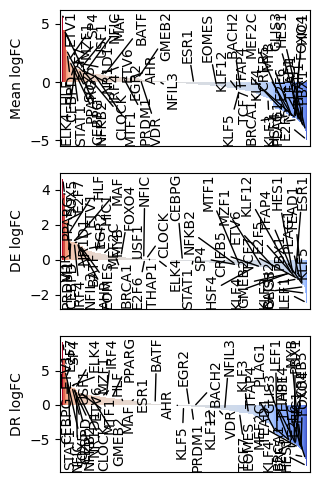

In [20]:
fig2=fig_diff_rank(data,annotate=annotate)


In [6]:
ct_order=["Naive_B", "Memory_B", "CD4_T", "CD8_T", "Th17", "Treg"]
tf=["TBX21", "MAF", "SOX4", "NFR1"]
#tf= ['PPARG', 'PBX2', 'NR1D1']
tf_sets = []
for i in tf:
    for j in [f"L_{x}" for x in ct_order[2:7]]:
        if deg[deg.index==i][j].any(): #check if any or more element are non-zero
            tf_sets.append((i, j))

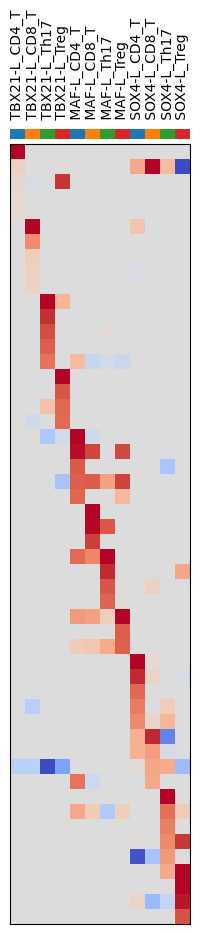

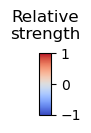

In [65]:
from dictys.plot.static import fig_heatmap_top
#Number of top targets for each TF
ntop=5
#Searching for top activated target genes only
direction=1

fig,fig_colorbar,net=fig_heatmap_top(d0,tf_sets,ntop=ntop,gann='',
                                     direction=direction,aspect=1)

### Draw target gene subnetwork from a TF
We can further zoom in for a particular TF in the relevant context and look at its targets.

#### Example 1: SPIB targets in B
As before, we first draw a large figure and annotate all genes to determine which we ultimately need.

In [6]:
nodes,edges=fig_subnet(d0,ax,'L_Treg',regulators=['FOXP3'], annotate = 'all')

In [80]:
edges[edges["Strength"] >0]["Regulator"].to_csv("CCR4_linked_TFs_Th17.txt", index = None)

In [82]:
edges

,Regulator,Target,Strength
0,AHR,CCR4,-0.057572
1,ARNT,CCR4,0.029449
2,BPTF,CCR4,-0.012271
3,CLOCK,CCR4,0.069529
4,EGR1,CCR4,0.001092
5,EGR2,CCR4,0.002109
6,EGR3,CCR4,-0.002906
7,ELK3,CCR4,-0.023421
8,EPAS1,CCR4,0.01042
9,GATA3,CCR4,0.056842


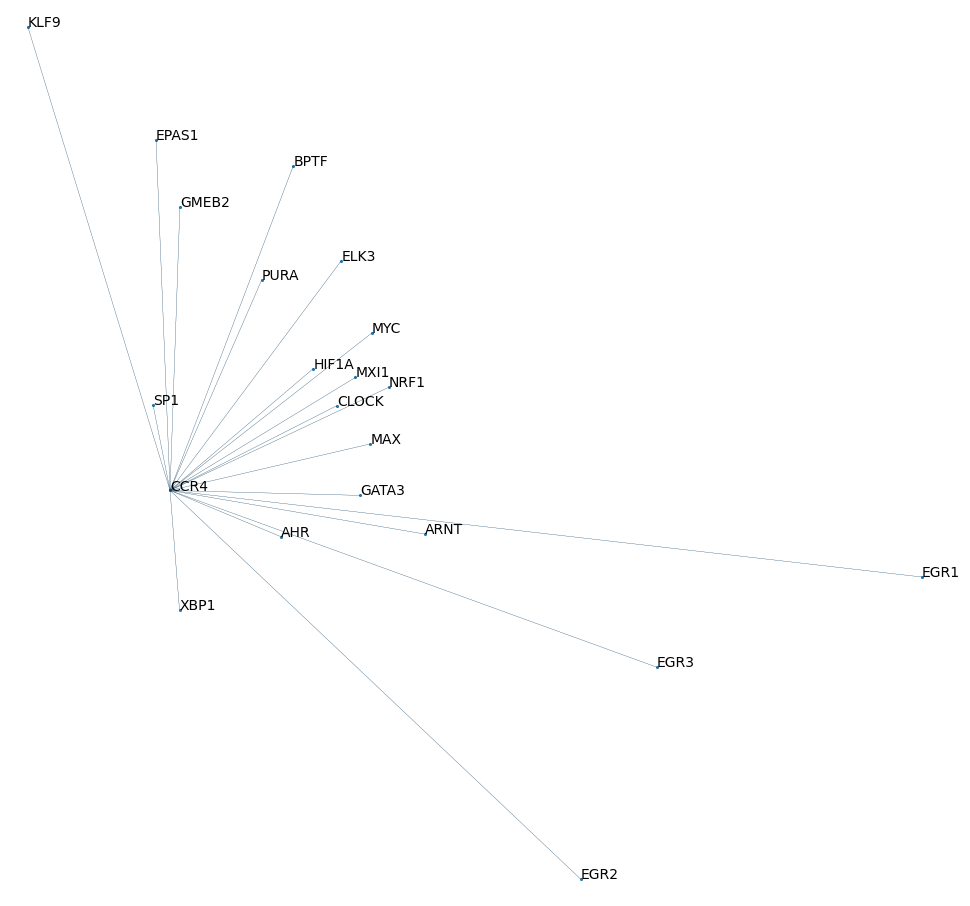

In [79]:
from dictys.plot.static import fig_subnet
fig=plt.figure(figsize=(12,12))
ax=fig.add_subplot(111)
nodes,edges=fig_subnet(d0,ax,'L_Th17', targets =['CCR4'], annotate='all',
                      sparsity=None)
                       #annotate=list(edges.loc[edges["Strength"] > 0, "Target"]) + ["FOXP3"]) 

In [16]:
edges.loc[edges["Strength"] > 0.1].to_csv("EGR2_network_strength_0.1.csv", index = None)

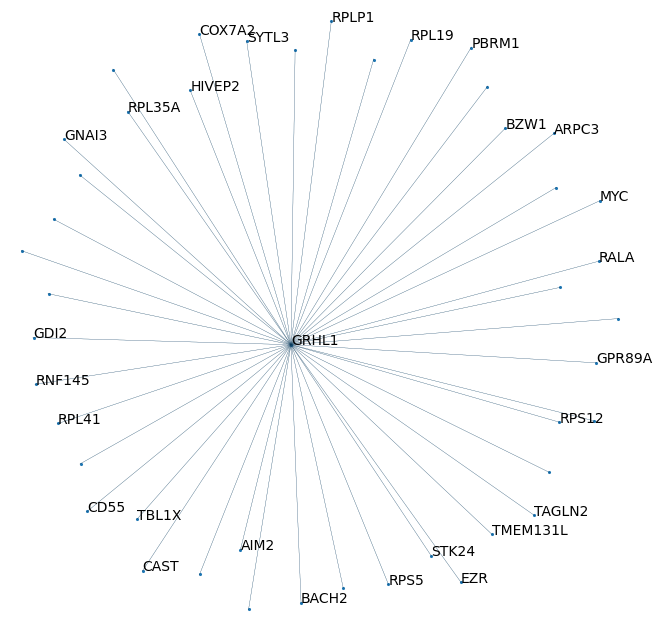

In [59]:
from dictys.plot.static import fig_subnet
fig=plt.figure(figsize=(8,8))
ax=fig.add_subplot(111)
nodes,edges=fig_subnet(d0,ax, "L_CD4_T", regulators=['GRHL1'],
                       sparsity = 0.015, #annotate='SYTL3,STK24,RALA,CAST,MYC'.split(',') + ["GRHL1"])
                           annotate=list(edges.loc[edges["Strength"] < 0, "Target"]) + ["GRHL1"])

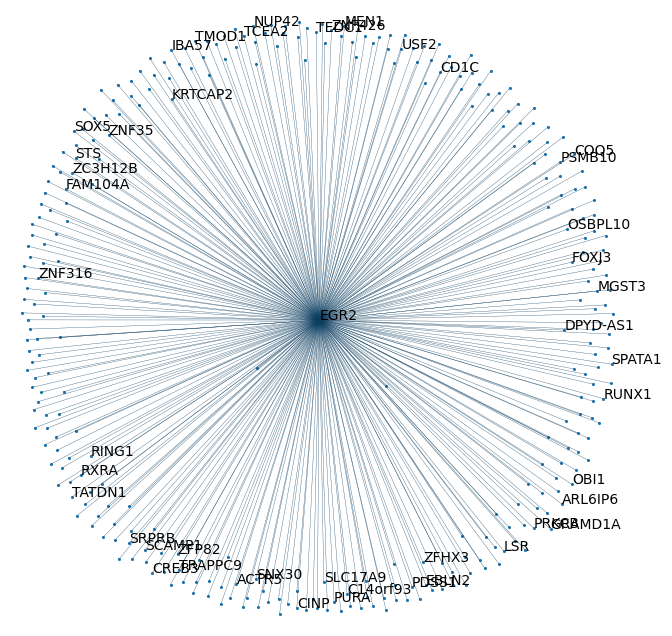

In [37]:
fig=plt.figure(figsize=(8,8))
ax=fig.add_subplot(111)
nodes,edges=fig_subnet(d0,ax, "L_Memory_B", regulators=['EGR2'],sparsity = 0.015, #annotate='all', 
                           annotate=list(edges.loc[edges["Strength"]>0, "Target"]) + ["EGR2"])
fig.show()

L_CD4_T
L_CD8_T
L_Naive_B
L_Memory_B


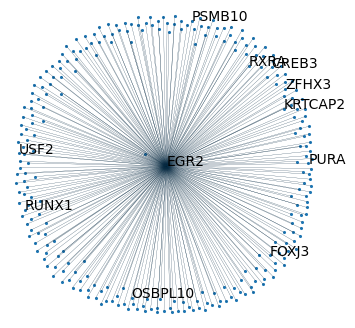

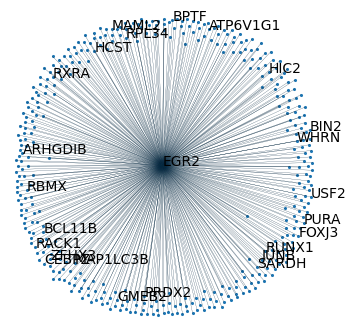

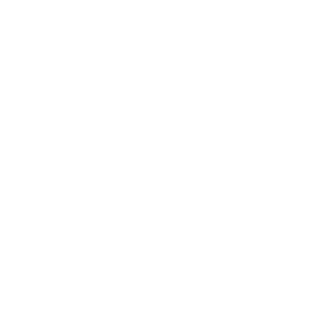

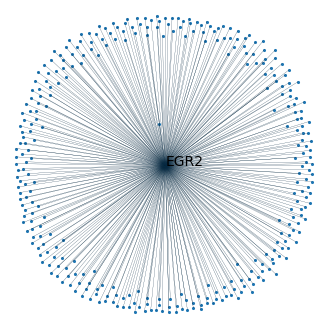

In [32]:
from dictys.plot.static import fig_subnet
for j in [f"L_{x}" for x in ct_order]:
    fig=plt.figure(figsize=(4,4))
    ax=fig.add_subplot(111)
    nodes,edges=fig_subnet(d0,ax, j, regulators=['EGR2'],sparsity = 0.015, #annotate='all', 
                           annotate=list(edges.loc[edges["Strength"]>0, "Target"]) + ["EGR2"])
    print(j)
    fig.show()

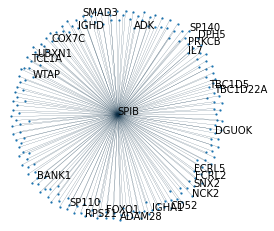

In [22]:
#Select genes to annotate
annotate='SPIB,IGHM,ZNF131,WDR48,UBXN1,ADK,GABPB1,COX7C,MED17,TCL1A,FLAD1,PAPOLA,NCK2,PHACTR1,CCR6,TBC1D22A,FCRL1,FCRL2,CD52,FCRL5,PRKCB,SP110,NCOA3,CD180,PIAS1,FCHSD2,BANK1,TBC1D5,IGHD,AIDA,SP100,ABCB4,SP140,FOXO1,MALT1,CNN2,DGUOK,ADAM28,SNX2,DPH5,IGHA1,RWDD3,SMAD3,KDM4C,WTAP,FLI1,IL7,POU2AF1,FAM30A,HLA-DRA,SP140L,RPS21'.split(',')
fig=plt.figure()
ax=fig.add_subplot(111)
nodes,edges=fig_subnet(d0,ax,'B',regulators=['SPIB'],annotate=annotate)


#### Example 2: FOXP3 in T regs

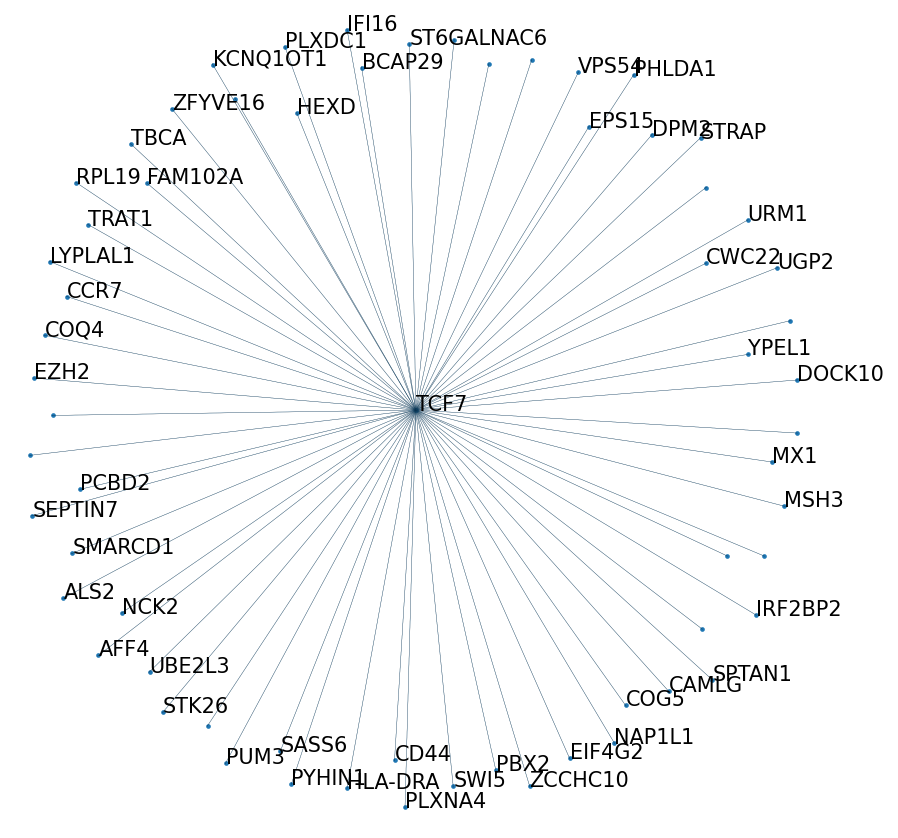

In [56]:
#FOXP3 does not have many strong regulation targets identified in T regs.
#We can make the network denser to reveal weaker regulations.
#Here we set a network sparsity cutoff that assigns 2% of all edges to be present.
sparsity=0.010
fig=plt.figure(figsize=(7,7), dpi=150)
ax=fig.add_subplot(111)
nodes,edges=fig_subnet(d0,ax,'lungs_CD4_T',regulators=['TCF7'],sparsity=sparsity,
                       #annotate=["IRF8", "BATF","IRF4", "IL12A","EBI3", "IL10", "TGFB1", "BCL3"])
                       annotate=list(edges.loc[edges["Strength"]>0, "Target"]) + ["TCF7"])


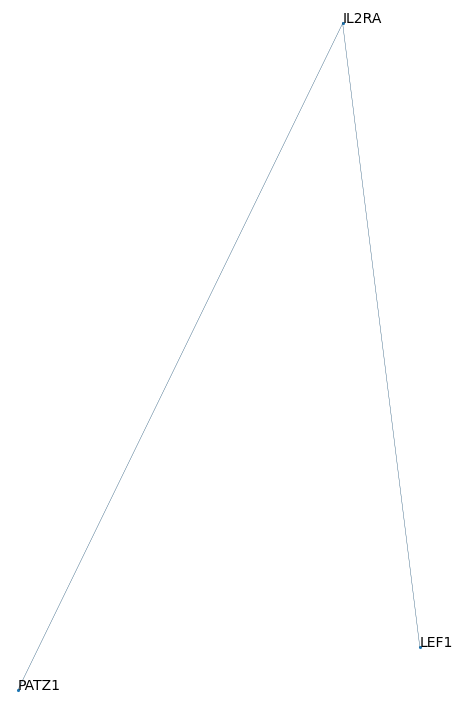

In [18]:
#Select genes to annotate
sparsity=0.010
fig=plt.figure(figsize=(9,9))
ax=fig.add_subplot(111)
nodes,edges=fig_subnet(d0,ax,'lungs_CD4_T',targets=['IL2RA'],sparsity=sparsity,
                       #annotate=["IRF8", "BATF","IRF4", "IL12A","EBI3", "IL10", "TGFB1", "BCL3"])
                       annotate="all")


### Download the inferred networks to share with collaborators and community
Others can load the networks and re-analyze/re-draw them with Dictys

In [25]:
from IPython.display import FileLink
FileLink('../output/static.h5')

../output/static.h5

### Alternatively, export the networks into tsv files

In [26]:
#Folder to export networks to
output_folder='../output/static'
#Choose which sparsities (proportion of edges present) to export network
#Use None to export continuous network
sparsities=[None,0.01]
d0.export(output_folder,sparsities=sparsities)
